## Projeto de Aprendizagem Estatística

**Gabriel R. M. Sanches (15453827)**

**Ian B. Loures (15459667)**

**Marcos O. Salvador (15474845)**

**Projeto MAE0501: Prevendo avaliações de filmes**

Roteiro do notebook:

1. Imports e funções globais
2. Dados e hold-out (20% das linhas separadas antes de qualquer análise)
3. Descrição dos dados
4. Análise exploratória (distribuições, correlação e relação das covariáveis com `stars`)
5. Multicolinearidade e criação de variáveis
6. Modelos, cada um em sua própria seção
7. Comparação final (validação cruzada e hold-out), README e Requirements

Todos os modelos são avaliados pela mesma função `evaluate`, com as mesmas partições de validação cruzada
(5 folds estratificados repetidos 3 vezes em `pure_train`). Cada resultado entra no dicionário `results`;
a comparação conjunta e a avaliação no hold-out aparecem só no final.

**Reprodutibilidade:** todo sorteio do notebook (divisão do hold-out, folds da validação cruzada, modelos com
componente aleatório e o jitter dos gráficos) tem semente fixa. Rodando o notebook do início
ao fim ("Restart & Run All"), os resultados saem idênticos a cada execução.

### Imports e Funções Globais

#### Bibliotecas

In [25]:
import math
import random
import warnings
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binned_statistic_2d, loguniform, randint, uniform

import statsmodels.formula.api as smf
from statsmodels.api import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.miscmodels.ordinal_model import OrderedModel

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import (
    train_test_split, KFold, RepeatedStratifiedKFold, StratifiedKFold,
    cross_val_score, cross_val_predict, RandomizedSearchCV,
)
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from scipy.stats import binned_statistic_2d, gaussian_kde
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

#### Configurações

In [26]:
# Identidade visual usada em todos os gráficos.
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=["#315C8C", "#24A19C", "#F4A261", "#D95D78", "#7B6DCC"],
)
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#344054",
    "text.color": "#243447",
    "grid.color": "#DCE3EA",
    "grid.alpha": 0.65,
})
pd.set_option("display.max_colwidth", None)

# Semente única do projeto. Todo objeto que sorteia algo recebe random_state=SEED;
# as duas linhas abaixo cobrem qualquer código que use os geradores globais.
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

# Semente dos MLPs (pesos iniciais e partição do early stopping).
MLP_SEED = 0
DATA = Path("")
DATA.mkdir(exist_ok=True)

#### Métrica e avaliação dos modelos

In [27]:
def rmse_clipped(y_true, y_pred):
    """
    RMSE after clipping predictions to [0, 5].

    Matches the competition metric, where predictions are limited to the
    valid star range before scoring.

    Parameters
    ----------
    y_true : array-like
        Observed star ratings.
    y_pred : array-like
        Raw model predictions (may fall outside [0, 5]).

    Returns
    -------
    float
        Root mean squared error between y_true and the clipped predictions.
    """
    return np.sqrt(mean_squared_error(y_true, np.clip(y_pred, 0, 5)))

scorer = make_scorer(rmse_clipped, greater_is_better=False)


evaluation_specs = {}
results = {}

def evaluate(name, model, X, y):
    """
    Cross-validated RMSE of `model` on (X, y), using the fixed folds in `cv`.

    Stores (mean CV RMSE, SE, variables used) in results[name] and the unfitted
    estimator + feature matrix in evaluation_specs[name] for the hold-out evaluation.
    Both are keyed by name, so re-running a cell overwrites the entry instead of
    duplicating it.
    """
    s = -cross_val_score(model, X, y, cv=cv, scoring=scorer)
    evaluation_specs[name] = (clone(model), X.copy())
    results[name] = (round(s.mean(), 4), round(s.std() / np.sqrt(len(s)), 4), ", ".join(X.columns))


def results_table(names=None):
    """
    Table of CV results stored in `results` (optionally only the rows in `names`).
    """
    table = pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T
    return table if names is None else table.loc[names]


def compare_models(names, reference):
    """
    CV results of the models in `names` and the RMSE gain over `reference`
    (gain = RMSE of the reference - RMSE of the model; positive means the model is better).
    """
    table = results_table(names).copy()
    table["CV RMSE"] = pd.to_numeric(table["CV RMSE"])
    table["Ganho de RMSE vs referência"] = (results[reference][0] - table["CV RMSE"]).round(4)
    return table


def oof_residuals(model, Xm, y):
    """
    Out-of-fold predictions and residuals for diagnostic plots.

    Each row is predicted by a model that did not see it, using a single
    stratified 5-fold split (cross_val_predict needs every row predicted
    exactly once, so it cannot use the repeated `cv` list). Uses the globals
    `SEED` and `strata` (genre + stars label) for reproducible, stratified folds.

    Parameters
    ----------
    model : sklearn estimator or Pipeline
        Unfitted model to diagnose.
    Xm : pd.DataFrame
        Feature matrix to fit on (pass the one you want to diagnose).
    y : pd.Series
        Target (stars).

    Returns
    -------
    pred : np.ndarray
        Out-of-fold predictions, clipped to [0, 5].
    resid : pd.Series
        y - pred. Positive values mean the model underpredicted.
    """
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    pred = np.clip(cross_val_predict(model, Xm, y, cv=skf.split(Xm, strata)), 0, 5)
    return pred, y - pred


def matching_feature_set(X_train_model, train_sets):
    """
    Name of the feature set (key of FEATURE_SETS) whose pure_train matrix equals `X_train_model`.
    """
    for name, X_k in train_sets.items():
        if X_train_model.equals(X_k):
            return name
    raise ValueError("Could not identify the feature set used by the model.")


def write_readme(results_df, path="README.md",
                 title="Projeto MAE0501: Prevendo avaliações de filmes"):

    rows = results_df.sort_values("CV RMSE").iterrows()

    table = [
        "| Model | CV RMSE | SE | Variables | Hold-out RMSE | Difference |",
        "|---|---:|---:|---|---:|---:|"
    ]

    for name, row in rows:
        table.append(
            f"| {name} "
            f"| {row['CV RMSE']:.4f} "
            f"| {row['SE']:.4f} "
            f"| {row['Variables']} "
            f"| {row['Hold-out RMSE']:.4f} "
            f"| {row['Difference (Hold-out - CV)']:.4f} |"
        )

    text = f"""# {title}

## Requirements

```bash
python -m pip install -r requirements.txt
```

## Resultados

RMSE por validação cruzada estratificada (5 folds, repetida 3 vezes) em `pure_train`; hold-out com 20% das linhas,
separado antes de qualquer análise. Todas as partições e modelos aleatórios têm semente fixa, então
rodar o notebook do início ao fim reproduz exatamente esta tabela.

{chr(10).join(table)}
"""
    Path(path).write_text(text, encoding="utf-8")
    print(f"{path} written ({len(results_df)} models)")

#### Engenharia de variáveis e matrizes de modelagem

Todas as variáveis derivadas são criadas por `add_features`, e cada matriz de modelagem (`X`, `X2`, `X3` e `X7`)
tem uma função `build_*` própria. Assim a mesma transformação é aplicada em `pure_train` e em `hold_out`,
e a avaliação final reconstrói automaticamente a matriz de cada modelo.

In [28]:
def share_match(data):
    """
    Share of the user's history in the movie's genre
    (share_action if genre == "action", share_comedy if "comedy", share_drama if "drama").
    """
    return data.apply(lambda r: r[f"share_{r['genre']}"], axis=1)


def add_features(data):
    """
    Return a copy of `data` with every derived variable used in the project.

    - log_user_n_ratings, log_movie_n_ratings: log(1 + counts), reduce the right skew.
    - share_match: affinity of the user with the movie's genre. Replaces the three
      share_* variables, which sum to 1 and are highly collinear.
    - ln_share_match: ln(share_match), linearizes the concave relation with stars.
    - age_x_year: interaction age x release_year.
    - age_at_release: user's age when the movie was released.
    - genre_comedy, genre_drama: dummies for genre (action is the reference).
    """
    out = data.copy()

    out["log_user_n_ratings"] = np.log1p(out["user_n_ratings"])

    out["log_movie_n_ratings"] = np.log1p(out["movie_n_ratings"])

    out["share_match"] = share_match(out)

    out["ln_share_match"] = np.log(out["share_match"])

    out["age_x_year"] = out["age"] * out["release_year"]

    out["age_at_release"] = out["age"] - (2026 - out["release_year"])

    for g in ["comedy", "drama"]:
        out[f"genre_{g}"] = (out["genre"] == g).astype(float)
    return out


# Variáveis originais (one-hot de genre, sem share_drama para evitar colinearidade perfeita).
COLS_X = ["user_avg_stars", "user_n_ratings", "age", "share_action", "share_comedy",
          "movie_avg_stars", "movie_n_ratings", "release_year",
          "genre_comedy", "genre_drama"]

# Regressão linear saturada - Todas as variáveis.
COLS_X7 = ["user_avg_stars", "log_user_n_ratings", "age", "ln_share_match",
           "age_x_year", "age_at_release", "movie_avg_stars", "log_movie_n_ratings",
           "genre_comedy", "genre_drama"]


def build_X(data):
    """Original variables + genre dummies."""
    return add_features(data)[COLS_X].copy()

def build_X2(data):
    """Original variables with share_match in place of share_action and share_comedy."""
    Xk = build_X(data).drop(columns=["share_action", "share_comedy"])
    Xk["share_match"] = share_match(data)
    return Xk

def build_X3(data):
    """Original variables with ln(share_match) in place of share_action and share_comedy."""
    Xk = build_X2(data)
    Xk["share_match"] = np.log(Xk["share_match"])
    return Xk

def build_X7(data):
    """Saturated linear model."""
    return add_features(data)[COLS_X7].copy()


FEATURE_SETS = {"X": build_X, "X2": build_X2, "X3": build_X3, "X7": build_X7}


def vif_table(Xv, constant=True):
    """
    Variance inflation factor of each column of `Xv`.
    With constant=True an intercept is added (and not reported).
    """
    Xv = Xv.astype(float)
    start = 0
    if constant:
        Xv = add_constant(Xv)
        start = 1
    return pd.DataFrame({
        "Variável": Xv.columns[start:],
        "VIF": [variance_inflation_factor(Xv.to_numpy(), i)
                for i in range(start, Xv.shape[1])],
    }).sort_values("VIF", ascending=False)

#### Estimadores próprios

A regressão ordinal (statsmodels) e o K-Means + K-NN não existem prontos no sklearn. As classes abaixo
dão a eles a mesma interface (`fit` / `predict`) dos demais modelos, para que passem pela mesma `evaluate`
e pela mesma avaliação no hold-out.

In [29]:
class OrdinalRegressor(RegressorMixin, BaseEstimator):
    """
    Ordinal logistic regression (statsmodels OrderedModel) with an sklearn interface.

    predict returns the expected number of stars: sum_k k * P(stars = k).
    """
    def __init__(self, distr="logit"):
        self.distr = distr

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.classes_ = np.sort(np.unique(y))
        y_cat = pd.Categorical(y, categories=self.classes_, ordered=True)
        self.result_ = OrderedModel(
            y_cat, np.asarray(X, dtype=float), distr=self.distr
        ).fit(method="bfgs", maxiter=1000, disp=False)
        return self

    def predict(self, X):
        proba = np.asarray(self.result_.predict(np.asarray(X, dtype=float)))
        return proba @ self.classes_


class KMeansCentroidRegressor(RegressorMixin, BaseEstimator):
    """
    K-Means + K-NN on the centroids.

    fit: K-Means finds `n_clusters` groups in the training rows.
    predict: a 1-NN on the centroids assigns each new row to the closest group,
    and the prediction is the mean of stars of the training rows in that group.
    """
    def __init__(self, n_clusters=6, random_state=None):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.kmeans_ = KMeans(n_clusters=self.n_clusters,
                              random_state=self.random_state, n_init=10).fit(X)
        self.knn_ = KNeighborsClassifier(n_neighbors=1).fit(
            self.kmeans_.cluster_centers_, np.arange(self.n_clusters))
        self.group_means_ = pd.Series(y).groupby(self.kmeans_.labels_).mean()
        self.global_mean_ = y.mean()
        return self

    def predict(self, X):
        groups = self.knn_.predict(np.asarray(X, dtype=float))
        return self.group_means_.reindex(groups).fillna(self.global_mean_).to_numpy()


class StepwiseLinearRegression(RegressorMixin, BaseEstimator):
    """
    Linear regression with bidirectional stepwise selection by AIC (like R's step()).

    Starts from the intercept-only model. At each step it tries adding each variable
    not yet in the model and removing each variable already in it, and keeps the move
    that lowers the AIC the most, AIC = n ln(RSS / n) + 2 (p + 1). It stops when no move
    lowers the AIC. Selection happens inside fit, so in cross-validation it is redone
    on the training rows of each fold.
    """
    def __init__(self, max_steps=100):
        self.max_steps = max_steps

    @staticmethod
    def _aic(X, y, cols):
        n = len(y)
        A = np.column_stack([np.ones(n)] + [X[:, j] for j in cols])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        rss = np.sum((y - A @ beta) ** 2)
        return n * np.log(rss / n) + 2 * A.shape[1]

    def fit(self, X, y):
        self.feature_names_in_ = np.array(getattr(X, "columns", range(np.shape(X)[1])), dtype=object)
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        selected, best = [], self._aic(X, y, [])
        for _ in range(self.max_steps):
            moves = [selected + [j] for j in range(X.shape[1]) if j not in selected]
            moves += [[k for k in selected if k != j] for j in selected]
            if not moves:
                break
            aics = [self._aic(X, y, m) for m in moves]
            i = int(np.argmin(aics))
            if aics[i] >= best - 1e-9:
                break
            selected, best = moves[i], aics[i]
        self.selected_ = sorted(selected)
        self.aic_ = best
        self.model_ = LinearRegression().fit(X[:, self.selected_], y) if self.selected_ else None
        self.mean_ = y.mean()
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if self.model_ is None:
            return np.full(len(X), self.mean_)
        return self.model_.predict(X[:, self.selected_])

    def selected_features(self):
        """Names of the selected variables, in the order of the columns of X."""
        return list(self.feature_names_in_[self.selected_])


#### Funções de gráficos

In [30]:
def plot_panel(data, cols, plot_func, ncols=3,
               title="Distribuição das variáveis numéricas", **kwargs):
    """Panel with one `plot_func` (e.g. sns.histplot) per column of `data`."""
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5.5 * ncols, 3.8 * nrows),
        squeeze=False
    )

    axes = axes.ravel()
    palette = sns.color_palette("husl", len(cols))

    for i, (ax, col) in enumerate(zip(axes, cols)):

        plot_func(
            data=data,
            x=col,
            ax=ax,
            color=palette[i],
            edgecolor="white",
            linewidth=0.6,
            **kwargs
        )

        nome = col.replace("_", " ").title()

        ax.set_title(nome, loc="left", fontsize=12, fontweight="bold", pad=10)
        ax.set_xlabel(nome, fontsize=10)
        ax.set_ylabel("Densidade" if kwargs.get("stat") == "density" else "Frequência")

        ax.grid(axis="y", alpha=0.2, linestyle="--")
        ax.grid(axis="x", visible=False)

        ax.tick_params(axis="both", labelsize=9)
        sns.despine(ax=ax)

    for ax in axes[len(cols):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=16, fontweight="bold", y=1.02)
    fig.tight_layout()
    plt.show()


def fix_axes(ax):
    """Fix axes to make the plot consistent."""
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=-0.15, top=5.15)

### Dados e Hold-Out

In [31]:
df = pd.read_csv("train.csv")

strata = df["genre"] + "_" + df["stars"].round().clip(lower=1).astype(int).astype(str)
print(strata.value_counts().min(), "linhas no menor estrato")

62 linhas no menor estrato


O menor estrato (gênero, estrelas) tem 62 linhas, então podemos tranquilamente dividir o conjunto de dados
entre treino e teste (hold-out). Por motivos empíricos, iremos segurar 20% das linhas para teste.

A partir daqui, **toda** a análise exploratória, a seleção de variáveis e a validação cruzada usam apenas
`pure_train`. O `hold_out` só é usado na comparação final, o que mantém essa estimativa independente da
escolha dos modelos.

In [32]:
pure_train, hold_out = train_test_split(
    df, test_size=0.2, stratify=strata, random_state=SEED
)
pure_train = pure_train.reset_index(drop=True)
hold_out = hold_out.reset_index(drop=True)

pure_train.to_csv(DATA / "pure_train.csv", index=False)
hold_out.to_csv(DATA / "hold_out.csv", index=False)
print("Treino puro:", pure_train.shape, "Hold-out:", hold_out.shape)

Treino puro: (3200, 12) Hold-out: (800, 12)


In [33]:
df = pure_train.copy()

X = build_X(df)
y = df["stars"]

strata = df["genre"] + "_" + df["stars"].round().clip(lower=1).astype(int).astype(str)
cv = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X, strata))

### Descrição dos Dados

O arquivo `train.csv` contém 4.000 observações (3.200 em `pure_train` e 800 em `hold_out`). Os exemplos abaixo
correspondem à primeira linha do arquivo. Cada linha representa uma combinação entre usuário e filme; a variável
resposta é a nota atribuída, de 0 a 5 estrelas. Os dados são fictícios e simulam avaliações de uma plataforma de filmes.

#### Identificação e resposta

| Variável | O que representa | Exemplo |
|---|---|---|
| `pair_id` | Identificador único da combinação usuário–filme. Serve para identificar a linha, não como preditor. | `P00001` |
| `stars` | Nota dada pelo usuário ao filme; variável que queremos explicar ou prever. | `3` estrelas |

#### Características do usuário

| Variável | O que representa | Exemplo |
|---|---|---|
| `user_avg_stars` | Média das notas que o usuário deu a outros filmes. | `2,99` estrelas |
| `user_n_ratings` | Quantidade de avaliações anteriores do usuário. | `15` avaliações |
| `age` | Idade do usuário, em anos. | `48` anos |
| `share_action` | Proporção de filmes de ação no histórico do usuário. | `0,315` = 31,5% |
| `share_comedy` | Proporção de comédias no histórico do usuário. | `0,501` = 50,1% |
| `share_drama` | Proporção de dramas no histórico do usuário. | `0,184` = 18,4% |

As três proporções de gênero somam 1. Por isso, ao usar intercepto em uma regressão, incluímos apenas duas delas
para evitar colinearidade perfeita.

#### Características do filme

| Variável | O que representa | Exemplo |
|---|---|---|
| `movie_avg_stars` | Média das notas recebidas anteriormente pelo filme. | `3,61` estrelas |
| `movie_n_ratings` | Quantidade de avaliações anteriores do filme. | `71` avaliações |
| `genre` | Gênero do filme: ação, comédia ou drama. | `drama` |
| `release_year` | Ano de lançamento do filme. | `2012` |

As médias e contagens anteriores são preditores importantes. Para evitar vazamento de informação, elas devem ter
sido calculadas sem incluir a nota que o modelo está tentando prever.

### Análise Exploratória

Toda a análise exploratória usa somente `pure_train` (`df`).

#### Estatísticas Descritivas

In [34]:
num = df.select_dtypes(include="number").columns.drop("stars")
cat = df.select_dtypes(include=["object", "category", "string"]).columns
cat = cat[~cat.isin(["pair_id", "stars"])]
df[num].describe().T

,count,mean,std,min,25%,50%,75%,max
user_avg_stars,3200.0,3.332472,0.705261,1.180,2.83000,3.340,3.80000,5.000
user_n_ratings,3200.0,57.632188,83.987678,3.000,14.00000,27.000,60.00000,1016.000
age,3200.0,36.442188,13.994342,16.000,24.00000,35.500,47.00000,79.000
share_action,3200.0,0.390455,0.190480,0.043,0.23775,0.369,0.53300,0.862
share_comedy,3200.0,0.295683,0.116084,0.071,0.20800,0.282,0.37025,0.722
share_drama,3200.0,0.313863,0.208906,0.031,0.13400,0.236,0.51000,0.819
movie_avg_stars,3200.0,3.011856,0.756041,0.310,2.51000,3.000,3.53000,5.000
movie_n_ratings,3200.0,54.559375,69.819776,5.000,16.00000,34.000,66.25000,1345.000
release_year,3200.0,2004.183750,14.962326,1970.000,1993.00000,2008.000,2017.00000,2024.000


#### Histogramas das Variáveis Numéricas

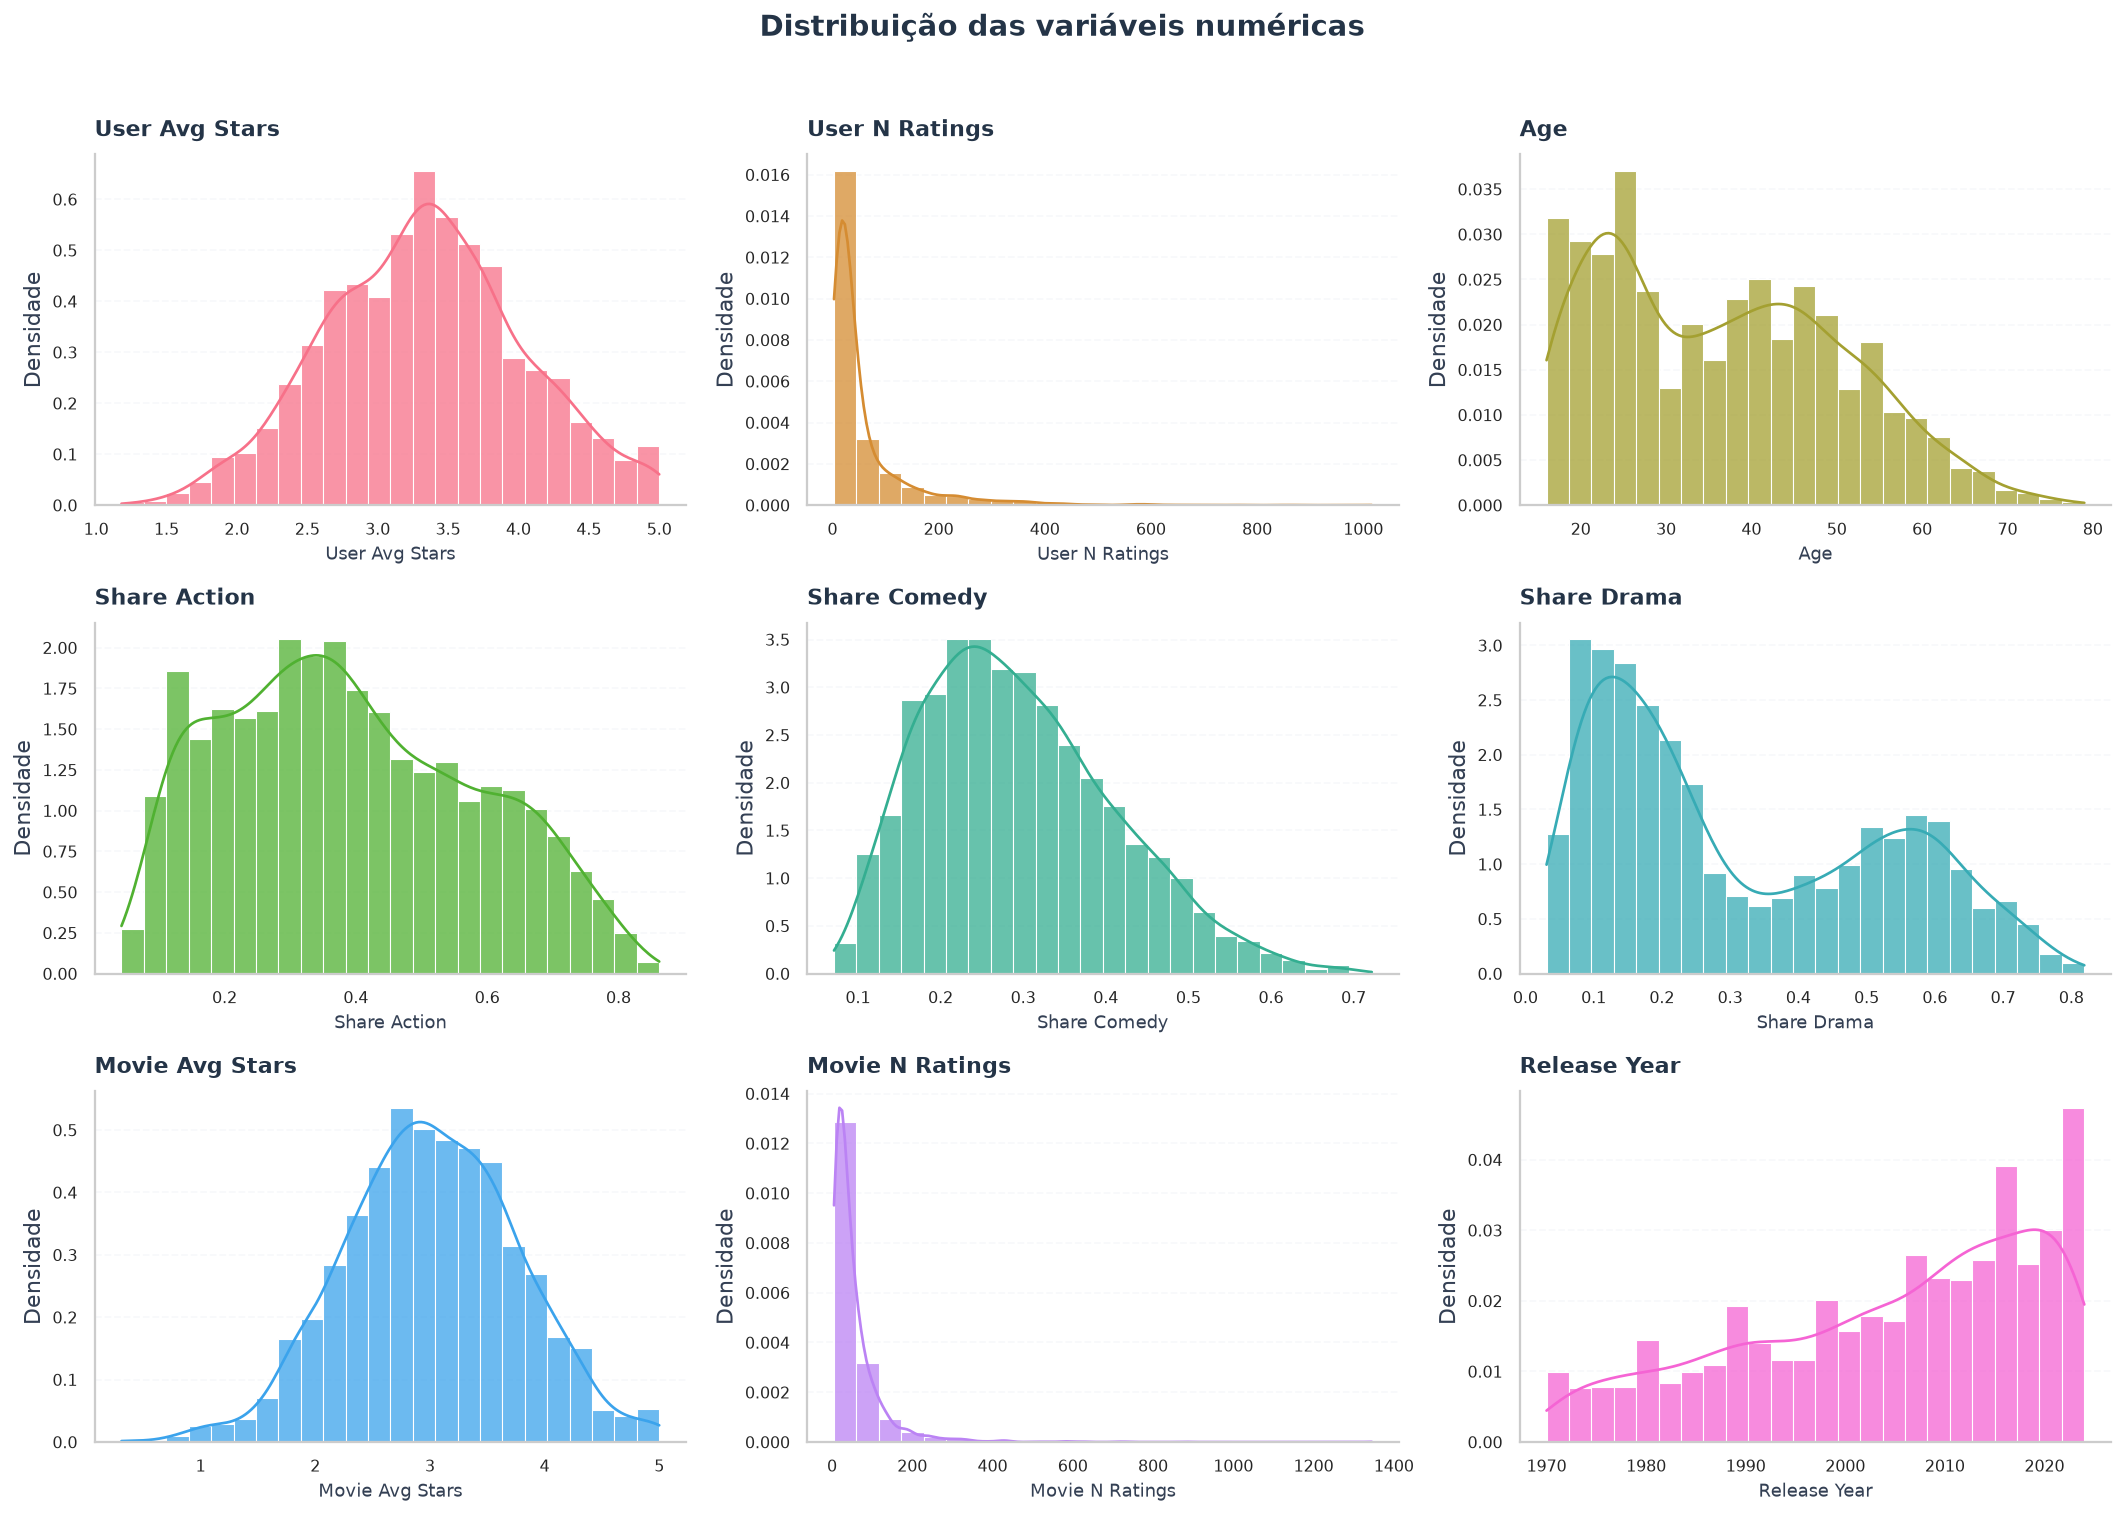

In [35]:
plot_panel(
    df,
    num,
    sns.histplot,
    kde=True,
    stat="density",
    bins=24,
    alpha=0.75
)

Para as variáveis de contagem, `movie_n_ratings` e `user_n_ratings`, vemos uma grande concentração em valores pequenos
(forte assimetria à direita). Isso sugere uma transformação logarítmica nessas variáveis, para reduzir a assimetria e
dar mais variabilidade e capacidade de análise aos nossos modelos.

#### Distribuição das Variáveis Categóricas e Ordinais

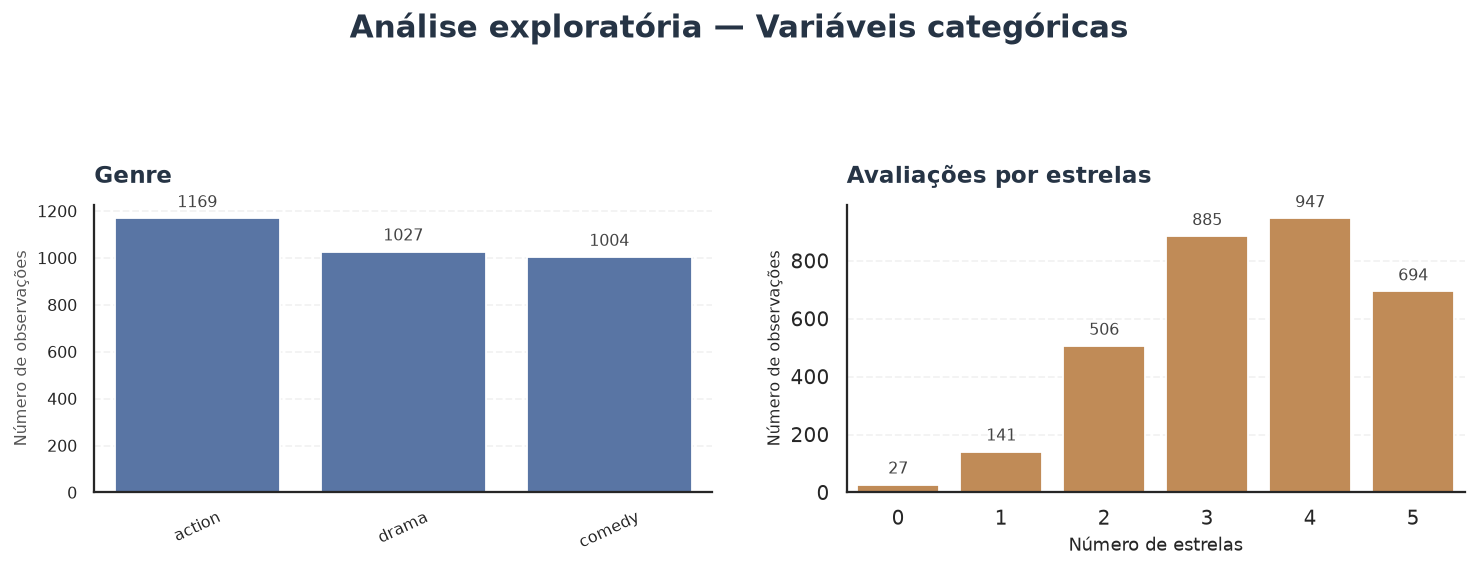

In [36]:
n = len(cat) + 1
ncols = min(n, 3)
nrows = math.ceil(n / ncols)
colors = sns.color_palette("deep", n_colors=n)

with sns.axes_style("white"):
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(6 * ncols, 4.5 * nrows),
        squeeze=False
    )
    axes = axes.flatten()

    # Variáveis categóricas
    for i, col in enumerate(cat):
        ax = axes[i]
        order = df[col].value_counts().index

        sns.countplot(
            data=df, x=col, order=order, color=colors[i],
            edgecolor="white", linewidth=1, ax=ax
        )
        for container in ax.containers:
            ax.bar_label(container, padding=4, fontsize=9, color="#444444")

        ax.set_title(col.replace("_", " ").title(), loc="left", fontsize=13,
                     fontweight="bold", color="#263445", pad=12)
        ax.set_xlabel("")
        ax.set_ylabel("Número de observações", fontsize=9, color="#555555")
        ax.tick_params(axis="x", rotation=25, labelsize=9)
        ax.tick_params(axis="y", labelsize=9)
        ax.grid(axis="y", linestyle="--", alpha=0.25)
        ax.set_axisbelow(True)
        sns.despine(ax=ax, left=False, bottom=False)

    # Avaliações
    ax = axes[len(cat)]
    sns.countplot(
        data=df, x="stars", order=sorted(df["stars"].dropna().unique()),
        color="#D28B45", edgecolor="white", linewidth=1, ax=ax
    )
    for container in ax.containers:
        ax.bar_label(container, padding=4, fontsize=9, color="#444444")

    ax.set_title("Avaliações por estrelas", loc="left", fontsize=13,
                 fontweight="bold", color="#263445", pad=12)
    ax.set_xlabel("Número de estrelas", fontsize=10)
    ax.set_ylabel("Número de observações", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

    # Ocultar espaços vazios
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.suptitle("Análise exploratória — Variáveis categóricas", fontsize=17,
                 fontweight="bold", color="#263445", y=1.02)
    fig.tight_layout(pad=2.5)
    plt.show()

#### Análise de Correlação das Covariáveis

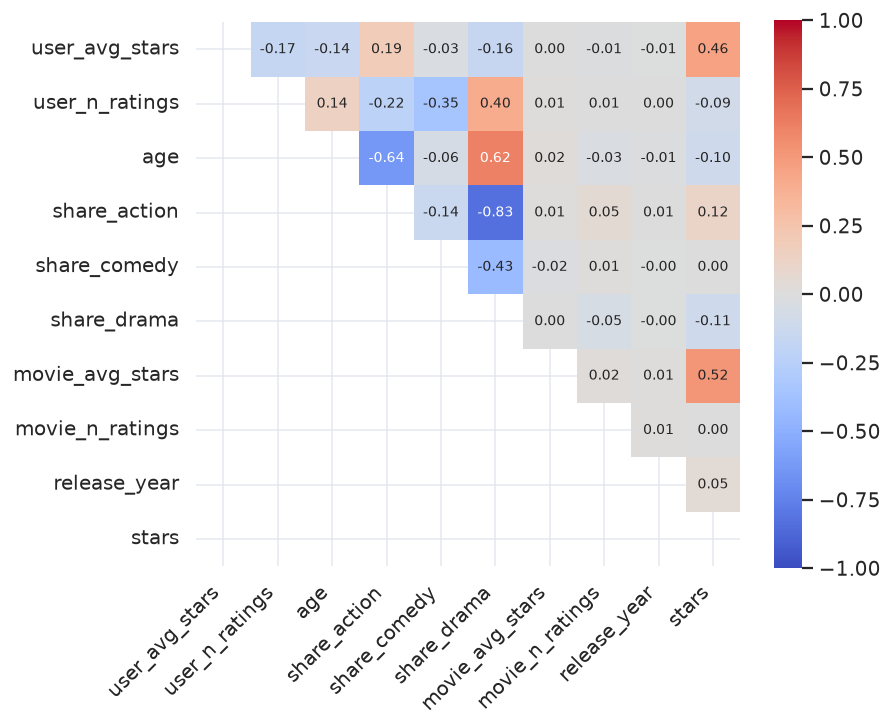

In [37]:
df_num = df[num]
corr = df.select_dtypes(include="number").corr()
mascara = np.tril(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

É possível observar que as variáveis `share_drama`, `share_comedy` e `share_action` são fortemente correlacionadas
entre si (as três somam 1), o que produz uma enorme multicolinearidade. Assim, é necessário tratar esse comportamento.

#### Tratamento de multicolinearidade

Através da métrica de VIF (Variance Inflation Factor), podemos observar quais das variáveis selecionadas produzem
maior colinearidade entre si.

In [38]:
# VIF sem intercepto com todas as variáveis numéricas originais.
vif_df = vif_table(df_num, constant=False)
vif_df

,Variável,VIF
5,share_drama,171421.997546
3,share_action,142502.594935
4,share_comedy,52926.506465
2,age,1.774515
1,user_n_ratings,1.287841
0,user_avg_stars,1.062459
7,movie_n_ratings,1.004953
6,movie_avg_stars,1.002621
8,release_year,1.001688


É notável o que acabamos de evidenciar. Sem perda de generalidade, retirando `share_comedy`:

In [39]:
# Com intercepto, retirando share_comedy (as três proporções somam 1).
vif_df2 = vif_table(df_num.drop(columns=["share_comedy"]))
vif_df2

,Variável,VIF
4,share_drama,4.125402
3,share_action,3.791616
2,age,1.774211
1,user_n_ratings,1.287838
0,user_avg_stars,1.062459
6,movie_n_ratings,1.004185
5,movie_avg_stars,1.001796
7,release_year,1.000376


O VIF diminui significativamente; ainda assim, temos uma perda de informação (uma das proporções sai do modelo) e
uma pequena multicolinearidade restante entre `share_action` e `share_drama`. Por isso incluímos uma nova variável,
`share_match`: a proporção do histórico do usuário no gênero do filme avaliado. Assim, não precisamos carregar
informação desnecessária, como as proporções dos gêneros que não são o do filme.

Para medir o ganho, comparamos a regressão linear com as variáveis originais (com `share_action` e `share_comedy`)
e a mesma regressão trocando essas proporções por `share_match`:

In [40]:
X2 = build_X2(df)

evaluate("Linear (Variáveis originais)",
    make_pipeline(StandardScaler(), LinearRegression()), X, y)
evaluate("Linear (Variáveis originais + share_match)",
    make_pipeline(StandardScaler(), LinearRegression()), X2, y)

compare_models(["Linear (Variáveis originais)", "Linear (Variáveis originais + share_match)"],
               reference="Linear (Variáveis originais)")

,CV RMSE,SE,Variables,Ganho de RMSE vs referência
Linear (Variáveis originais),0.8270,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama",0.0000
Linear (Variáveis originais + share_match),0.6578,0.0027,"user_avg_stars, user_n_ratings, age, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match",0.1692


**Comentários**

A coluna de ganho é positiva quando o modelo tem RMSE menor que a referência. Trocar as proporções `share_*` por
`share_match` reduz o RMSE de validação cruzada usando uma variável a menos: a afinidade do usuário com o gênero
do filme resume melhor a informação de gênero do que as proporções separadas, e ainda elimina a multicolinearidade.

#### Relação das Covariáveis com `stars`

In [41]:
rng = np.random.default_rng(SEED)

# Jittered stars: adicionamos pequenos distúrbios no valor de estrelas para a nuvem de pontos ficar mais visível
y_jit = (df["stars"] + rng.uniform(-0.15, 0.15, len(df))).clip(0, 5)

# share_match: incluímos uma variável nova (proporção do histórico do usuário no gênero do filme)
df["share_match"] = share_match(df)
df["log_user_n_ratings"] = np.log1p(df["user_n_ratings"])
df["log_movie_n_ratings"] = np.log1p(df["movie_n_ratings"])


feats = ["user_avg_stars", "age",
         "share_action", "share_comedy", "share_drama",
         "movie_avg_stars", "release_year",
         "share_match", "log_user_n_ratings", "log_movie_n_ratings"]

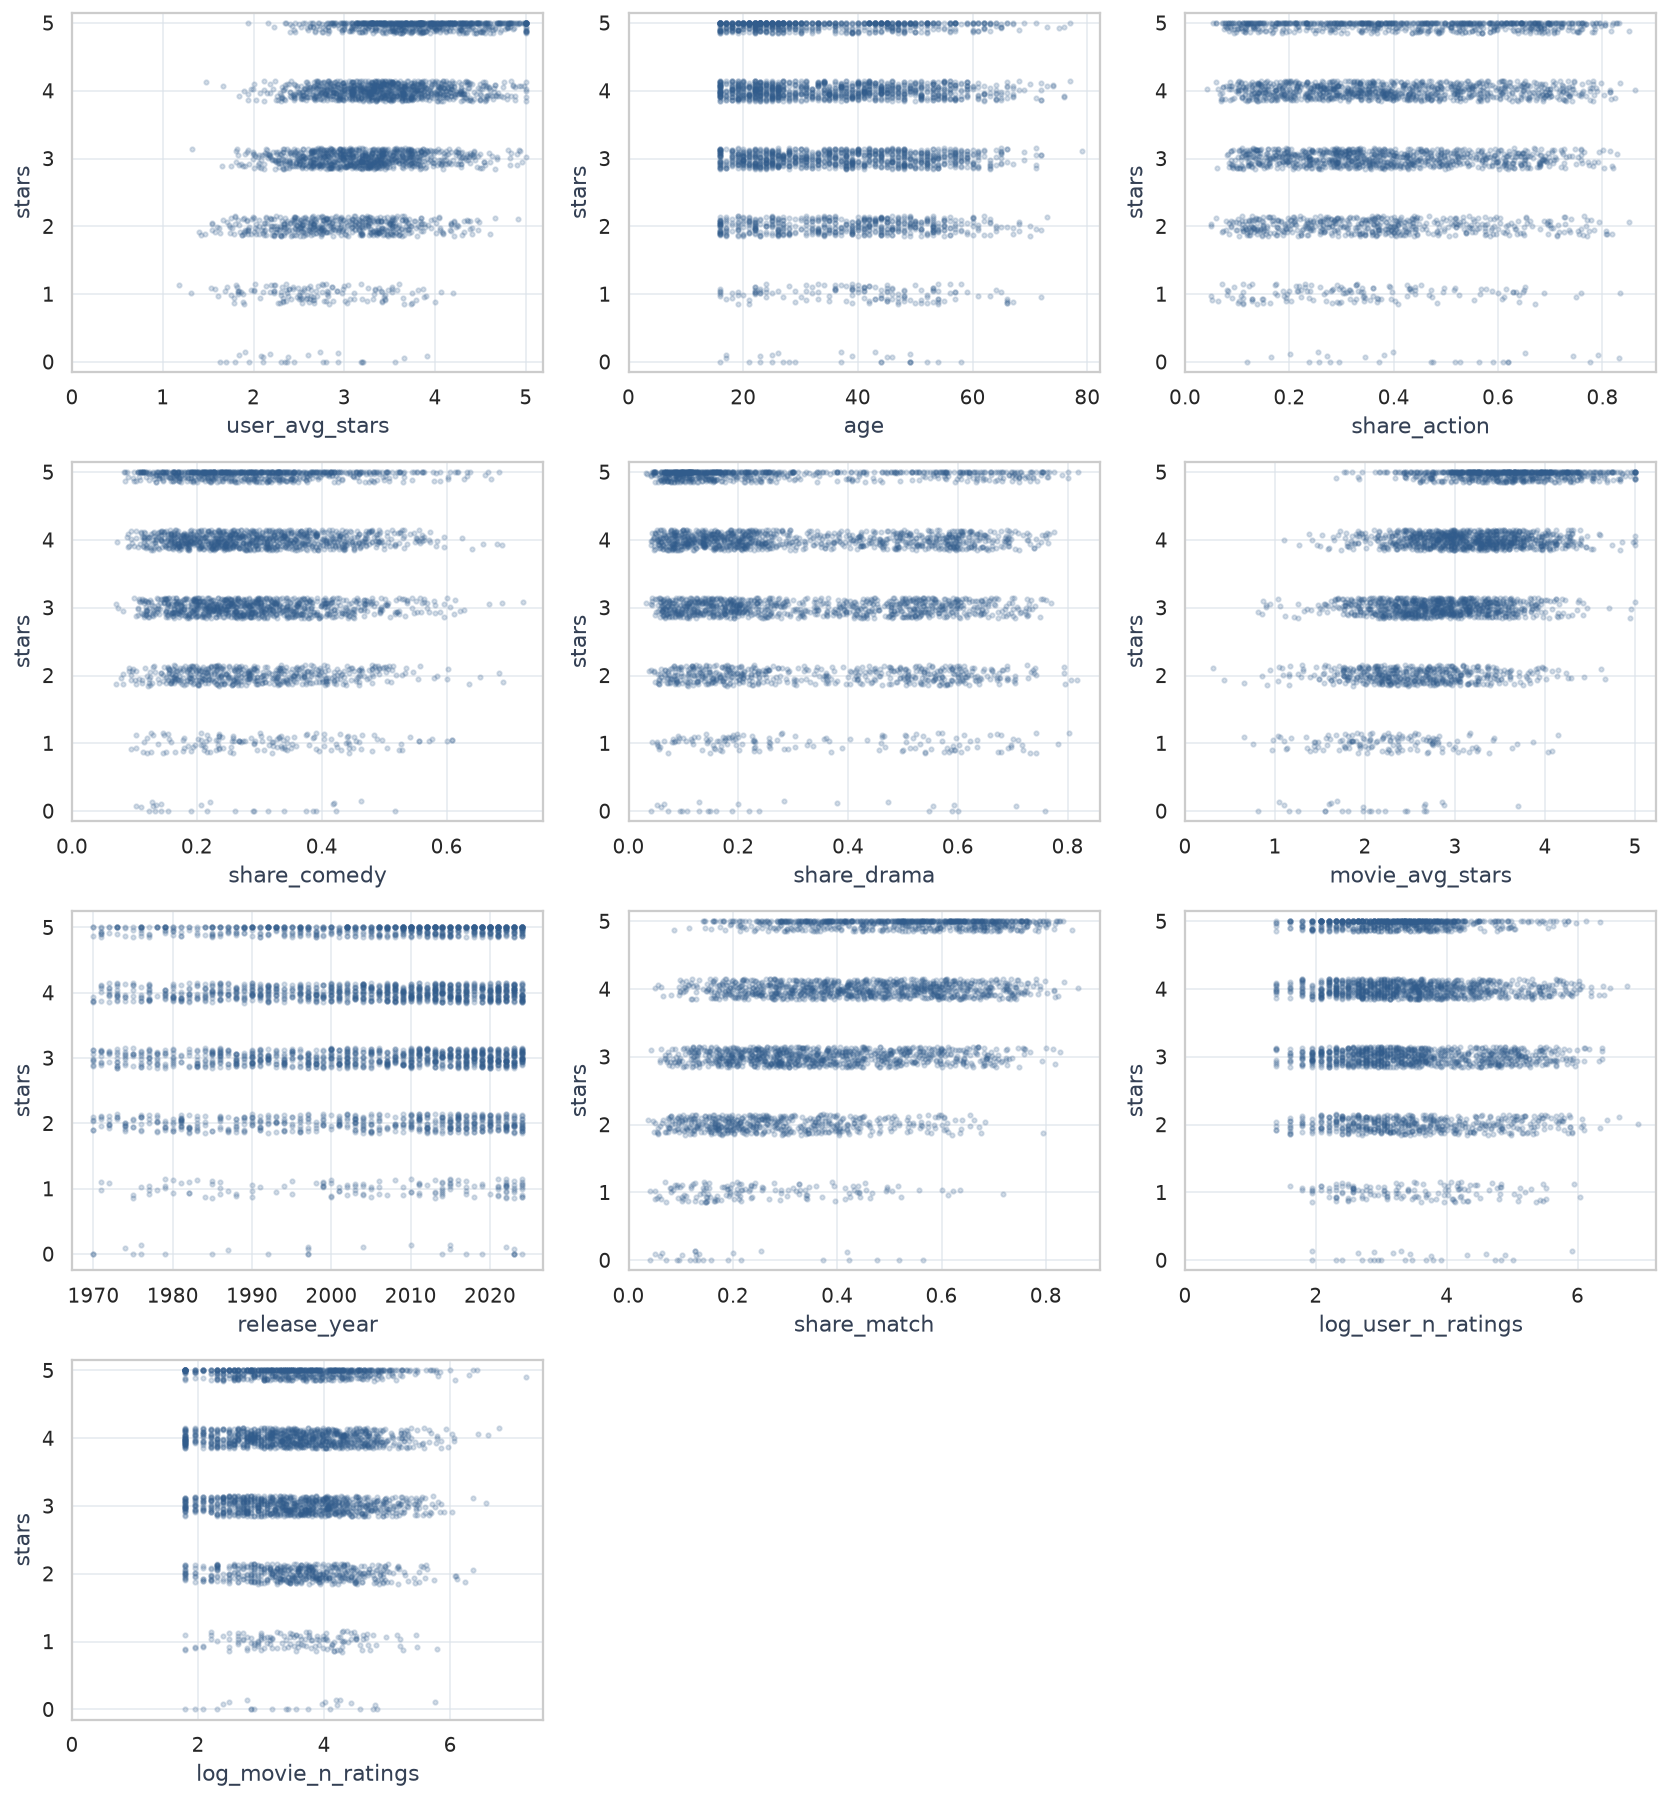

In [42]:
fig, axes = plt.subplots(4, 3, figsize=(13, 14))
for ax, f in zip(axes.ravel(), feats):
    ax.scatter(df[f], y_jit, alpha=0.2, s=6)
    ax.set_xlabel(f); ax.set_ylabel("stars")
    if f != "release_year":
        fix_axes(ax)
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

- Como esperado, usuários que tem uma maior média de estrelas costumam dar estrelas maiores; o mesmo acontece com filmes que tem avaliação média maior;
- Há uma impressão de que usuários com mais avaliações dão mais estrelas 3, mas isso pode ser apenas pela própria distribuição de estrelas; o mesmo acontece com filmes mais avaliados;
- Em primeiro momento, usuários mais velhos parecem não gostar de dar estrelas baixas. Apesar disso, é inconclusivo: temos poucas estrelas baixas e poucos usuários mais velhos. As outras faixas estão bem distribuídas;
- Há uma desconcentração de pontos para usuários com alta proporção de filmes de ação assistidos e estrelas baixas, especialmente a partir de 2 estrelas; para a proporção de filmes de comédia, parece ter-se uma uniformidade maior ao longo de uma mesma estrela; o mesmo acontece com os filmes de drama;
- O ano do filme parece não ter relação com o número de estrelas dado;
- O último gráfico mostra no eixo x a porcentagem do gênero assistido do usuário que é o gênero do filme. Ou seja, o quanto o usuário assistiu daquele gênero tem relação positiva com o número de estrelas.

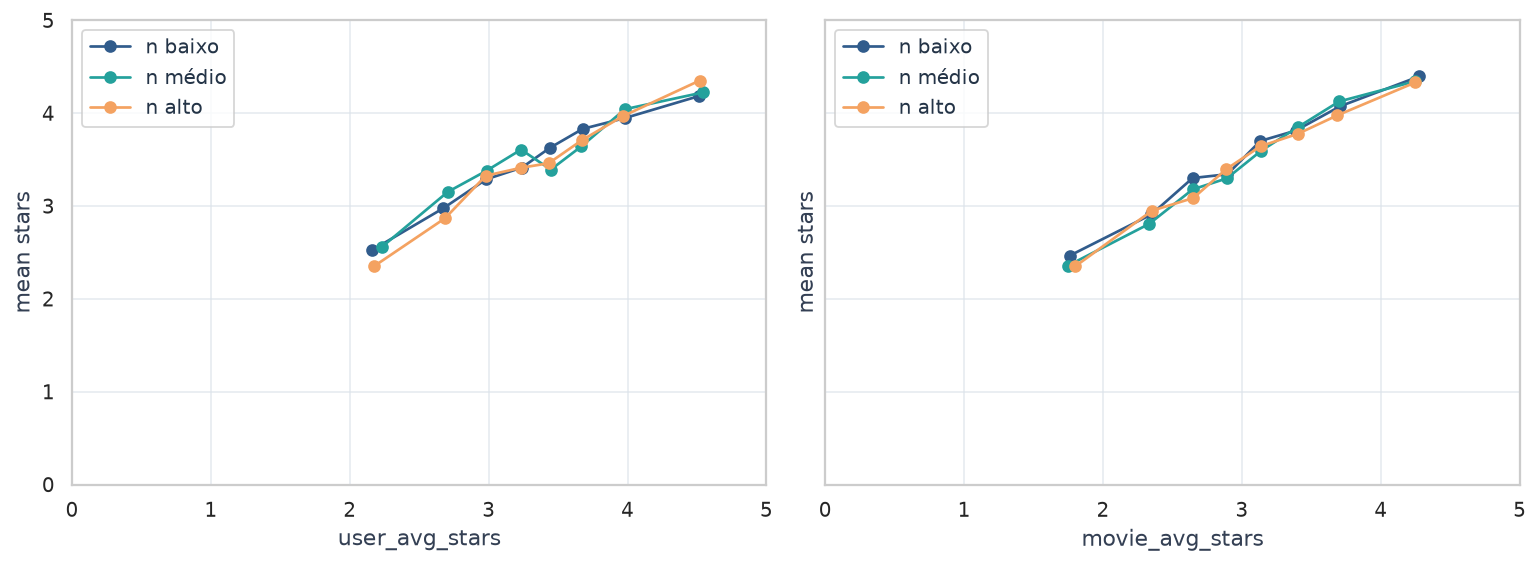

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (avg, n) in zip(axes, [("user_avg_stars", "log_user_n_ratings"),
                               ("movie_avg_stars", "log_movie_n_ratings")]):
    d = df.copy()
    d["n_grp"] = pd.qcut(d[n], 3, labels=["n baixo", "n médio", "n alto"])
    d["bin"] = pd.qcut(d[avg], 8, duplicates="drop")
    for g, sub in d.groupby("n_grp", observed=True):
        m = sub.groupby("bin", observed=True).agg(x=(avg, "mean"), y=("stars", "mean"))
        ax.plot(m["x"], m["y"], "o-", label=g)
    ax.set_xlabel(avg); ax.set_ylabel("mean stars"); ax.legend()
    ax.set_ylim(bottom=0, top=5)
    ax.set_xlim(left=0, right=5)
plt.tight_layout(); plt.show()

Os gráficos acima mostram linhas com baixo, médio, e alto número de avaliações (pelo usuário e para o filme), em relação ao número médio de estrelas. Como podemos ver, a confiabilidade da avaliação parece não ter relação com o número de avaliações, o que é surpreendente e descarta a possibilidade de interação.

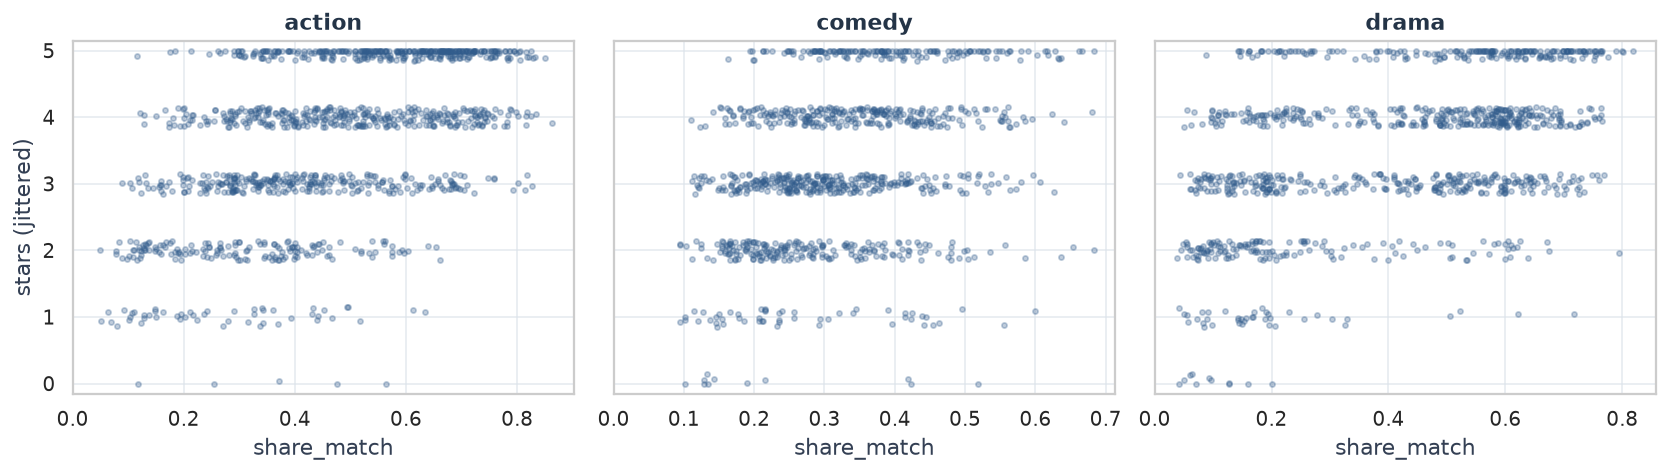

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, g in zip(axes, ["action", "comedy", "drama"]):
    d = df[df["genre"] == g]
    yj = (d["stars"] + rng.uniform(-0.15, 0.15, len(d))).clip(0, 5)
    ax.scatter(d["share_match"], yj, alpha=0.3, s=8)
    ax.set_title(g); ax.set_xlabel("share_match")
    fix_axes(ax)
axes[0].set_ylabel("stars (jittered)")
plt.tight_layout(); plt.show()

Como visto anteriormente, especialmente para o gênero ação, usuários dão mais estrelas para gêneros que assistem mais. Apesar de haver algumas assimetrias em cada gênero eles se comportam de forma bem distribuída sem padrões claros tão expressivos

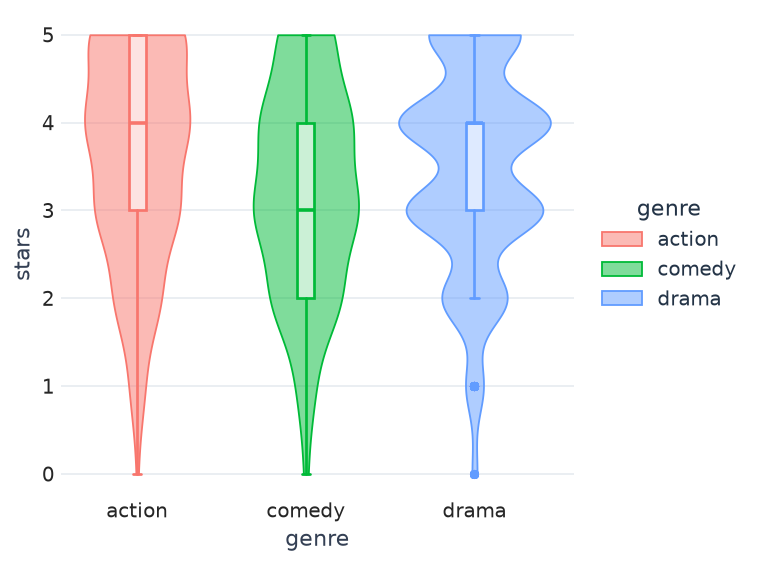

In [45]:
ordem = sorted(df["genre"].unique())
paleta = dict(zip(ordem, ["#F8766D", "#00BA38", "#619CFF"]))
grupos = [df.loc[df["genre"] == g, "stars"].to_numpy() for g in ordem]

def largura_nrd0(x):
    sd = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    h = min(sd, iqr / 1.34) if iqr > 0 else sd
    return 0.9 * h * len(x) ** (-0.2)

# FATOR DE SUAVIZAÇÃO: Aumente este valor para deixar mais suave (ex: 1.5, 2.0)
fator_suavizacao = 1.8

curvas = []
for x in grupos:
    # Multiplicamos o resultado da largura de banda pelo fator para suavizar a curva
    largura_ajustada = (largura_nrd0(x) / np.std(x, ddof=1)) * fator_suavizacao
    kde = gaussian_kde(x, bw_method=largura_ajustada)
    grade = np.linspace(x.min(), x.max(), 512)
    curvas.append((grade, kde(grade)))
dens_max = max(d.max() for _, d in curvas)

fig, ax = plt.subplots(figsize=(6, 4.5))
for i, (g, (grade, dens)) in enumerate(zip(ordem, curvas)):
    meia_largura = dens / dens_max * 0.45
    ax.fill_betweenx(grade, i - meia_largura, i + meia_largura,
                     facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], linewidth=1)

caixas = ax.boxplot(grupos, positions=range(len(ordem)), widths=0.1, patch_artist=True,
                    manage_ticks=False)
for i, g in enumerate(ordem):
    cor = paleta[g]
    caixas["boxes"][i].set(facecolor=to_rgba("white", 0.6), edgecolor=cor, linewidth=1.5)
    caixas["medians"][i].set(color=cor, linewidth=2)
    for parte in ("whiskers", "caps"):
        for linha in caixas[parte][2 * i:2 * i + 2]:
            linha.set(color=cor, linewidth=1.5)
    caixas["fliers"][i].set(marker="o", markersize=4, markerfacecolor=cor, markeredgecolor=cor)

ax.set_xticks(range(len(ordem)))
ax.set_xticklabels(ordem)
ax.set_yticks(range(0, 6))
ax.set_xlabel("genre")
ax.set_ylabel("stars")
ax.grid(axis="x", visible=False)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
ax.legend(handles=[Patch(facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], label=g) for g in ordem],
          title="genre", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.show()

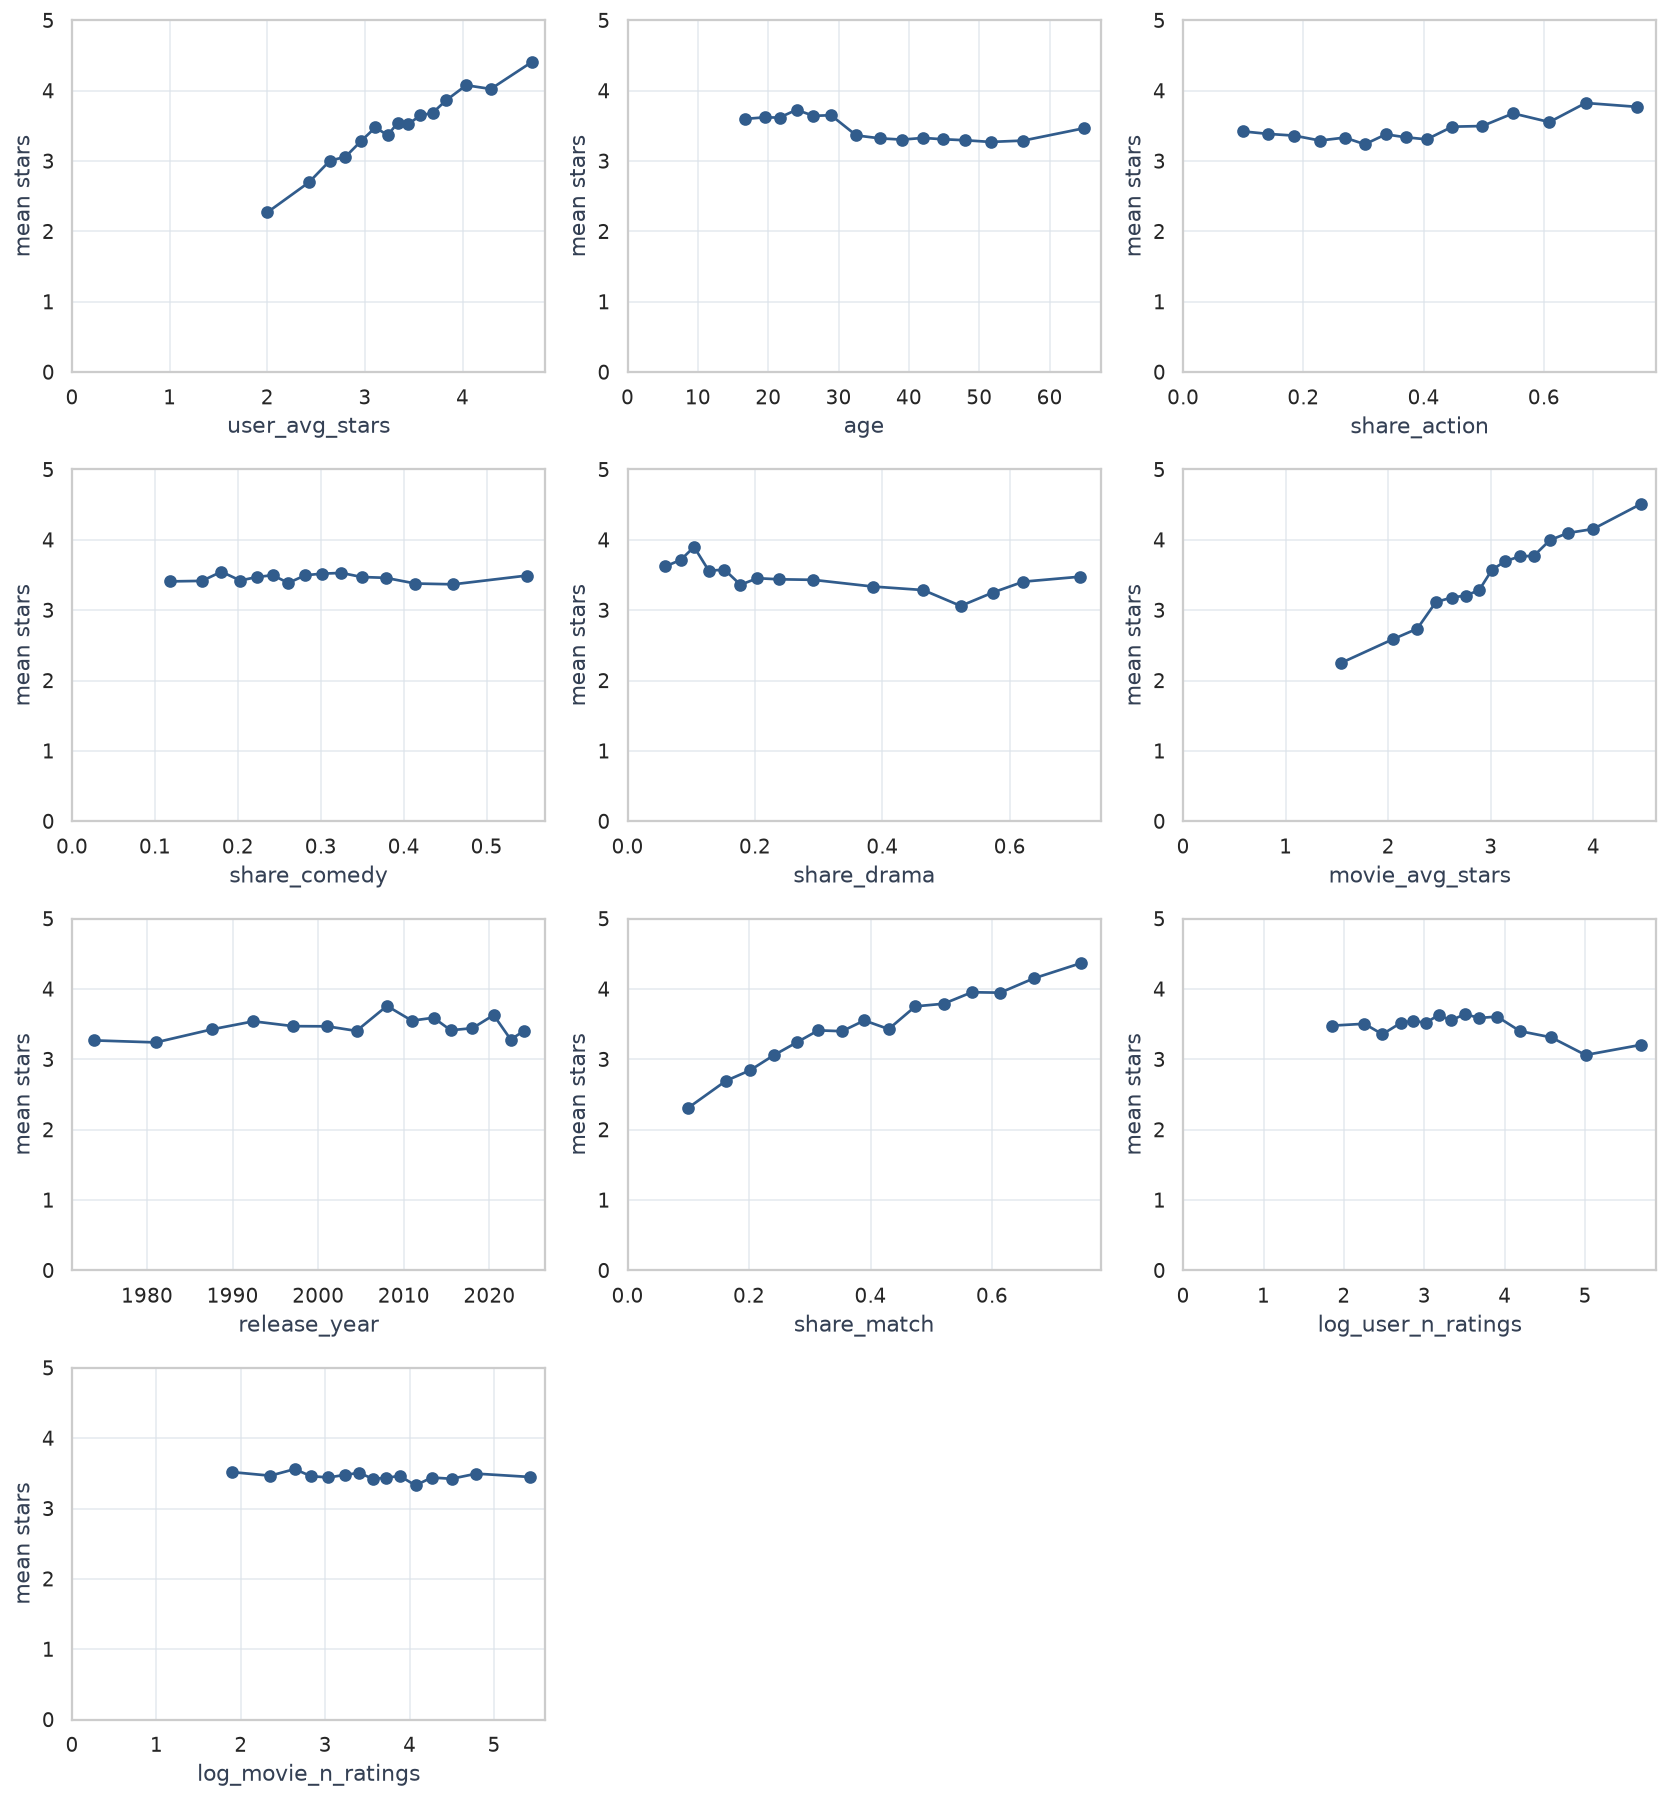

In [46]:
fig, axes = plt.subplots(4, 3, figsize=(13, 14))
for ax, f in zip(axes.ravel(), feats):
    b = pd.qcut(df[f], 15, duplicates="drop")
    m = df.groupby(b, observed=True).agg(x=(f, "mean"), y=("stars", "mean"))
    ax.plot(m["x"], m["y"], "o-")
    ax.set_xlabel(f); ax.set_ylabel("mean stars")
    if f != "release_year":
        fix_axes(ax)
    ax.set_ylim(0, 5)
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

O painel acima condensa parte das informações que obtivemos acima, sem a bagunça da nuvem de pontos. Dividimos as variáveis em 15 pontos e calculamos a média. Note que as 3 variáveis mais importantes analisadas são: as médias de avaliação e a proporção de filmes assistidos do mesmo gênero. Existem pequenas flutuações em release_year e age que podem indicar uma pequena relação até conjunta. As variáveis de contagem mostrando padrões assimétricos concentrados que indicam que a transformação log realmente ajustaria melhor. 

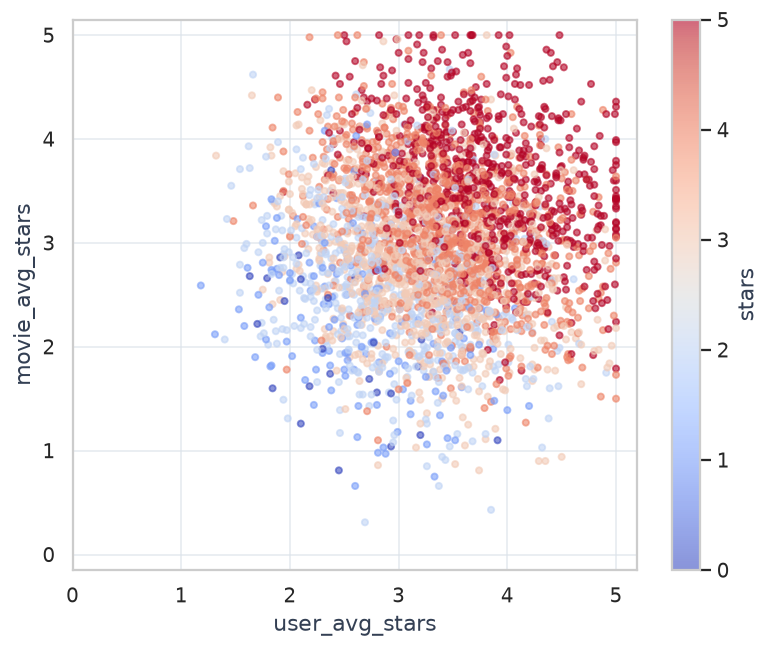

In [47]:
plt.figure(figsize=(7, 5.5))
sc = plt.scatter(df["user_avg_stars"], df["movie_avg_stars"],
                 c=df["stars"], cmap="coolwarm", alpha=0.6, s=12)
plt.colorbar(sc, label="stars")
plt.xlabel("user_avg_stars"); plt.ylabel("movie_avg_stars")
fix_axes(plt.gca())
plt.show()

Parece que o efeito das variáveis de média é aditivo. Ainda assim, há uma mistura de cores no meio e nos cantos. Uma das hipóteses é que a outra variável importante, `share_match`, explica boa parte dessa confusão.

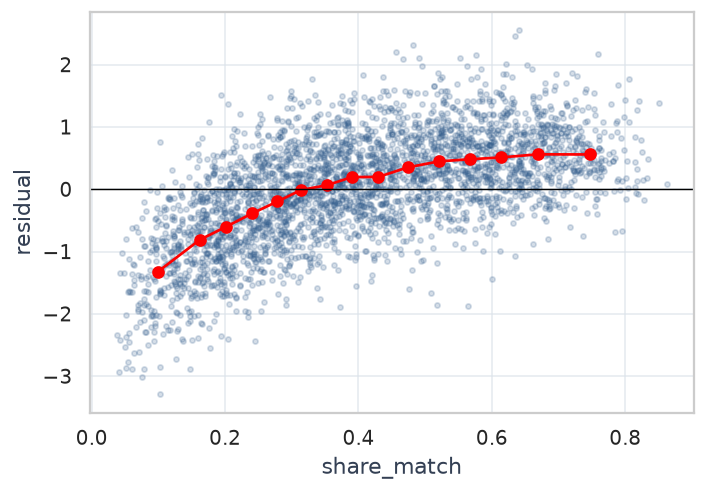

In [48]:
X_res = df[["user_avg_stars", "movie_avg_stars"]]
resid = df["stars"] - LinearRegression().fit(X_res, df["stars"]).predict(X_res)

plt.figure(figsize=(6, 4))
plt.scatter(df["share_match"], resid, alpha=0.2, s=8)
b = pd.qcut(df["share_match"], 15, duplicates="drop")
m = pd.DataFrame({"x": df["share_match"], "r": resid}).groupby(b, observed=True).mean()
plt.plot(m["x"], m["r"], "r-o")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("share_match"); plt.ylabel("residual")
plt.show()

Acima temos os resíduos de um modelo linear usando as médias, plotados contra `share_match`. Note que há um efeito forte. Na verdade, há várias interpretações importantes que surgem desse gráfico:

- Usuários que assistem pouco do gênero avaliam baixo; a partir de um certo momento, a adição de mais porcentagem de gênero não aumenta tanto a nota dada;
- A linha plotada dos resíduos cruza o eixo x em `share_match` próxima de 0.33 $\left(\frac{1}{3}\right)$, que é o caso em que não há preferência de gênero;
- Ainda há uma grande dispersão nos resíduos.

O primeiro ponto descreve uma relação côncava: os resíduos crescem rápido para valores pequenos de `share_match` e
se achatam para valores grandes. Uma transformação na variável `share_match` parece de bom tom para manter um padrão
claro nos pontos, e o logaritmo natural lineariza exatamente esse comportamento.

Para verificar, comparamos o modelo anterior (variáveis originais + `share_match`, já avaliado na seção de
multicolinearidade) com o mesmo modelo usando ln(`share_match`):

In [49]:
X3 = build_X3(df)

evaluate("Linear (Variáveis originais + ln(share_match))",
    make_pipeline(StandardScaler(), LinearRegression()), X3, y)

compare_models(["Linear (Variáveis originais + share_match)",
                "Linear (Variáveis originais + ln(share_match))"],
               reference="Linear (Variáveis originais + share_match)")

,CV RMSE,SE,Variables,Ganho de RMSE vs referência
Linear (Variáveis originais + share_match),0.6578,0.0027,"user_avg_stars, user_n_ratings, age, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match",0.0000
Linear (Variáveis originais + ln(share_match)),0.6185,0.0027,"user_avg_stars, user_n_ratings, age, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match",0.0393


**Comentários**

Com ln(`share_match`), o RMSE cai em relação ao modelo com `share_match` na escala original (ganho positivo): a
relação côncava observada nos resíduos passa a ser capturada pelo termo linear. Por isso, os diagnósticos a seguir
partem do modelo com ln(`share_match`) (`X3`).

#### Precisamos de mais variáveis?

In [50]:
model = make_pipeline(StandardScaler(), LinearRegression())
pred, resid = oof_residuals(model, X3, y)

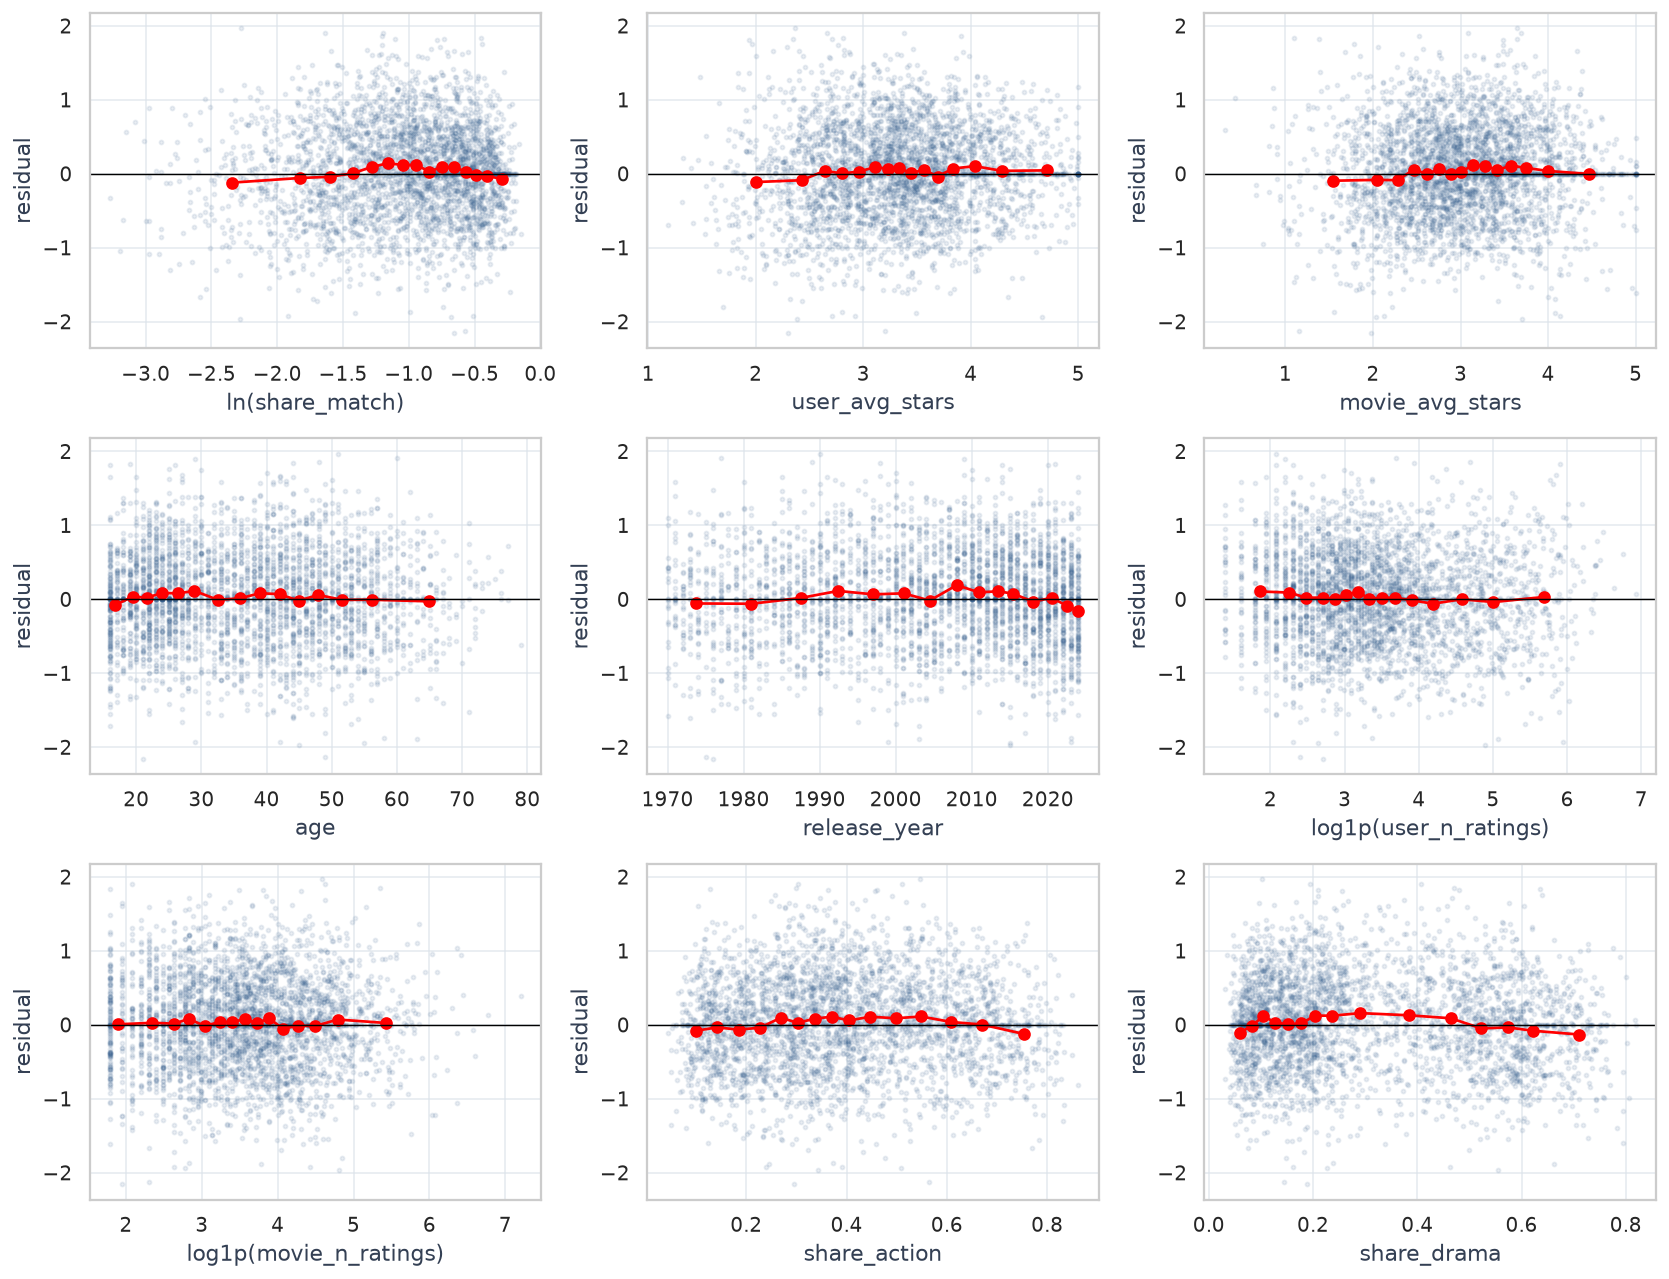

In [51]:
cands = {
    "ln(share_match)": X3["share_match"],
    "user_avg_stars": X2["user_avg_stars"],
    "movie_avg_stars": X2["movie_avg_stars"],
    "age": X2["age"],
    "release_year": X2["release_year"],
    "log1p(user_n_ratings)": np.log1p(X2["user_n_ratings"]),
    "log1p(movie_n_ratings)": np.log1p(X2["movie_n_ratings"]),
    "share_action": df["share_action"],
    "share_drama": df["share_drama"],
}

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, (name, xf) in zip(axes.ravel(), cands.items()):
    b = pd.qcut(xf, 15, duplicates="drop")
    m = pd.DataFrame({"x": xf, "r": resid}).groupby(b, observed=True).mean()
    ax.scatter(xf, resid, alpha=0.1, s=5)
    ax.plot(m["x"], m["r"], "r-o")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(name); ax.set_ylabel("residual")
plt.tight_layout(); plt.show()

Vemos que nenhuma das variáveis, nem algumas de suas modificações, puxa o resíduo para algum lado: a média dos
resíduos fica próxima de zero em toda a faixa de cada uma. Para melhorar, devemos considerar outros modelos ou criar
novas variáveis a partir das que temos.

### Análise das variáveis expressadas no modelo

Agora olhamos o resíduo contra ln(`share_match`) separando cada variável em faixas (baixa, média e alta) ou por
gênero. Se as curvas de faixas diferentes se separarem, há indício de interação entre a variável e `share_match`.

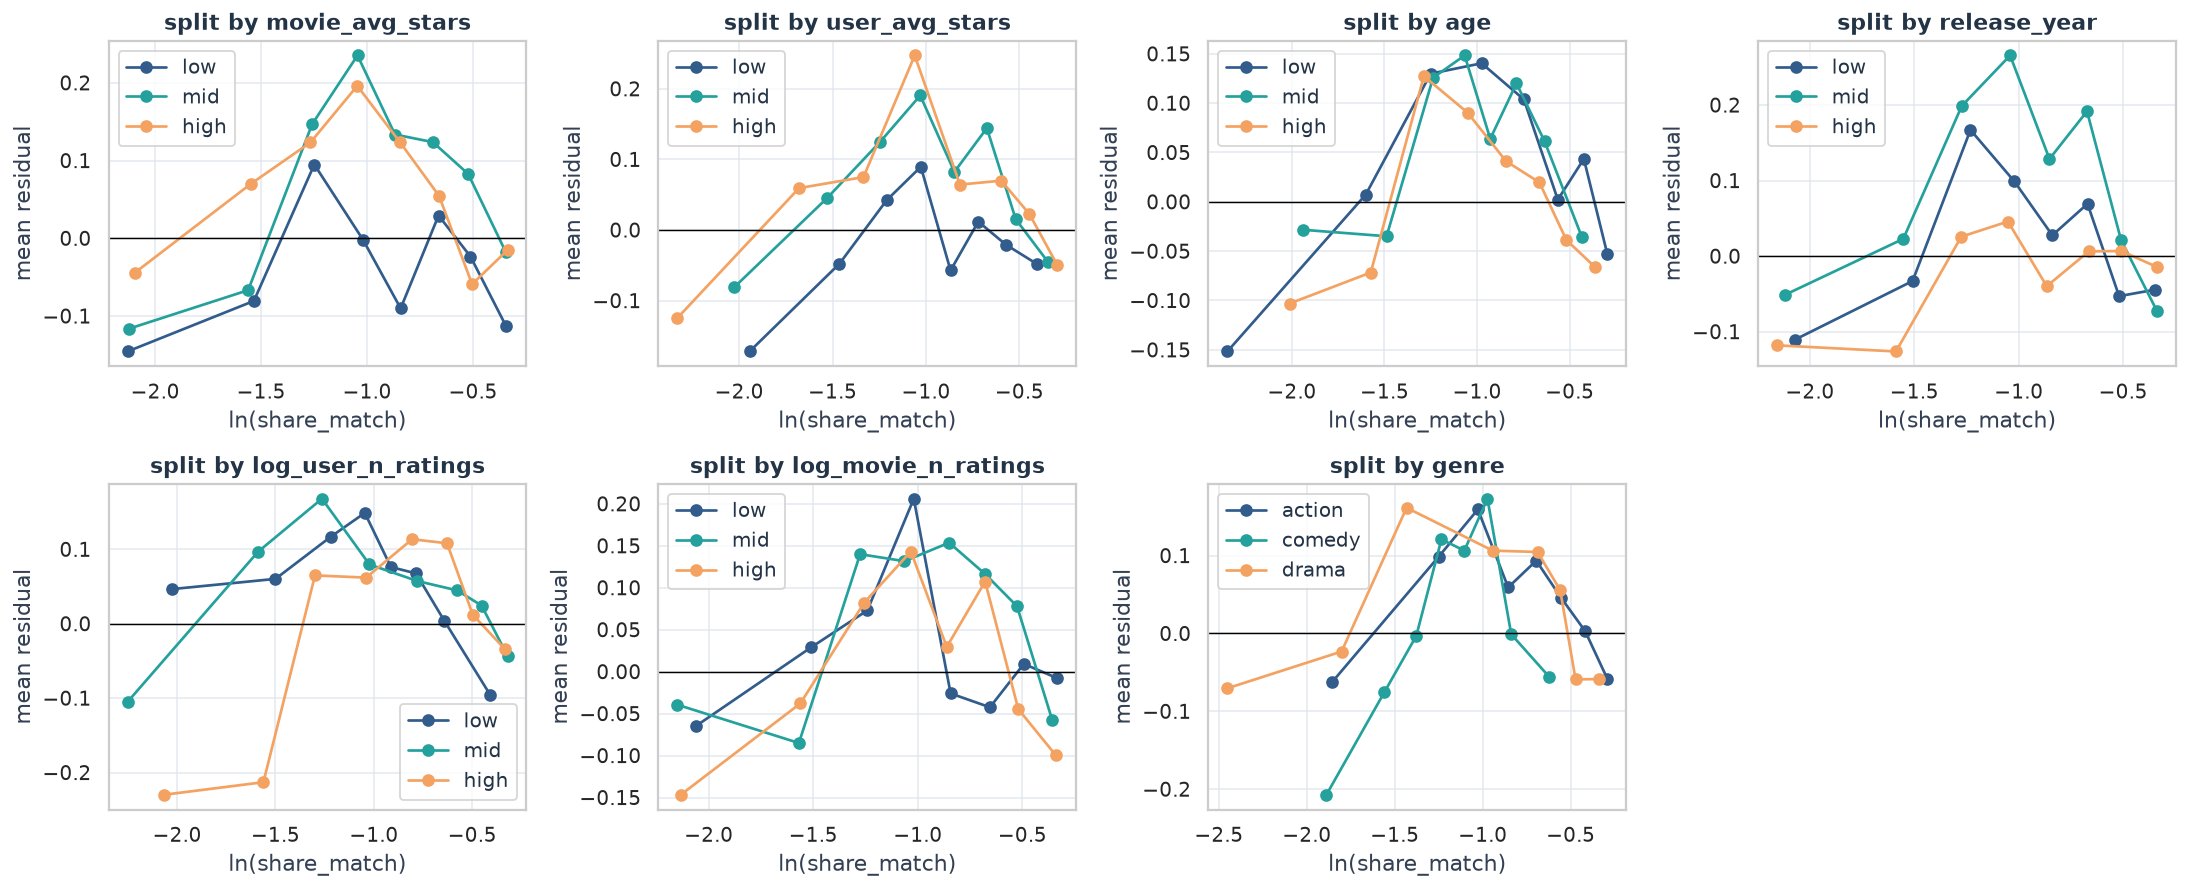

In [52]:
model = make_pipeline(StandardScaler(), LinearRegression())
pred, resid = oof_residuals(model, X3, y)
resid = np.asarray(resid)

cands = {
    "movie_avg_stars": X3["movie_avg_stars"],
    "user_avg_stars": X3["user_avg_stars"],
    "age": X3["age"],
    "release_year": X3["release_year"],
    "log_user_n_ratings": np.log(X3["user_n_ratings"] + 1),
    "log_movie_n_ratings": np.log(X3["movie_n_ratings"] + 1),
    "genre": df["genre"],
}

xs = X3["share_match"].to_numpy()               # ln(share_match)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (name, g) in zip(axes.ravel(), cands.items()):
    if name == "genre":
        labels = sorted(g.unique())
    else:
        g = pd.qcut(g, 3, labels=["low", "mid", "high"])
        labels = ["low", "mid", "high"]
    for lab in labels:
        idx = (g == lab).to_numpy()
        xi, ri = xs[idx], resid[idx]
        b = pd.qcut(xi, 8, duplicates="drop")    # positional, no index involved
        m = pd.DataFrame({"x": xi, "r": ri}).groupby(b, observed=True).mean()
        ax.plot(m["x"], m["r"], "o-", label=lab)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"split by {name}")
    ax.set_xlabel("ln(share_match)"); ax.set_ylabel("mean residual")
    ax.legend()
for ax in axes.ravel()[len(cands):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

Os perfis não expressam relação clara entre as variáveis (as curvas das faixas praticamente se sobrepõem), assim nos
resta trabalhar somente com o que temos, capturando e testando possibilidades através de seleções intuitivas.

Uma ideia é levar em conta a idade e o ano de lançamento por meio de uma interação, para tentar capturar a idade do
usuário na época e tratar uma interação dessas variáveis. Criamos assim:

- `age_at_release`: equivalente à idade que o usuário possuía quando o filme foi lançado;
- `age_x_year`: interação de idade e ano de lançamento do filme;

e englobamos em nossa análise para dar continuidade:

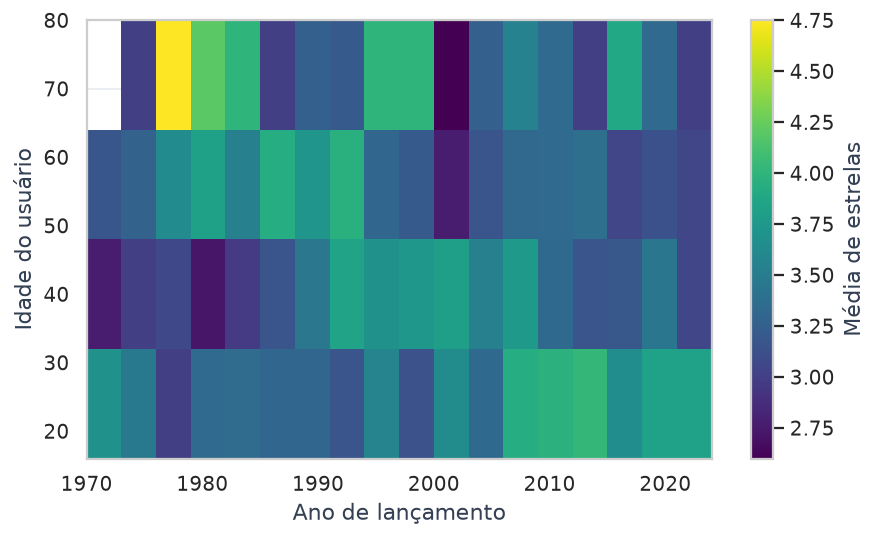

In [53]:
bins_x = np.arange(df["release_year"].min(), df["release_year"].max() + 3, 3)
bins_y = np.arange(df["age"].min(), df["age"].max() + 16, 16)
estatistica, bx, by, _ = binned_statistic_2d(
    df["release_year"], df["age"], df["stars"],
    statistic="mean", bins=[bins_x, bins_y]
)
fig, ax = plt.subplots(figsize=(7, 4.3))
malha = ax.pcolormesh(bx, by, estatistica.T, cmap="viridis")
fig.colorbar(malha, ax=ax, label="Média de estrelas")
ax.set_xlabel("Ano de lançamento")
ax.set_ylabel("Idade do usuário")
plt.tight_layout()
plt.show()

Essa relação é realmente interessante, pois mostra que usuários mais jovens tendem a dar notas mais altas para filmes lançados recentemente, enquanto usuários mais velhos tendem a ser mais críticos com filmes recentes. Além disso, há uma faixa de idade (aproximadamente entre 30 e 50 anos) que parece ser mais neutra em relação ao ano de lançamento, dando notas mais consistentes independentemente do ano do filme.

##### Analisando as variáveis novas 

In [54]:
df_feat = add_features(df)
df_feat[["log_user_n_ratings", "log_movie_n_ratings", "share_match",
         "age_x_year", "age_at_release"]].describe().T

,count,mean,std,min,25%,50%,75%,max
log_user_n_ratings,3200.0,3.463149,1.043895,1.386294,2.708050,3.332205,4.110874,6.924612
log_movie_n_ratings,3200.0,3.557656,0.940861,1.791759,2.833213,3.555348,4.208396,7.204893
share_match,3200.0,0.403375,0.187669,0.038000,0.249000,0.389000,0.555000,0.862000
age_x_year,3200.0,73034.833750,28046.873032,31520.000000,48282.000000,70934.000000,94211.500000,159817.000000
age_at_release,3200.0,14.625937,20.388699,-40.000000,1.000000,15.000000,29.000000,76.000000


#### Nova Relação Multicolinear 

In [55]:
vif_df3 = vif_table(df_feat[[
    "user_avg_stars", "log_user_n_ratings", "movie_avg_stars", "log_movie_n_ratings",
    "age_x_year", "age_at_release", "share_match", "age",
]])
vif_df3

,Variável,VIF
4,age_x_year,17980.392584
7,age,17337.591789
5,age_at_release,14.275420
1,log_user_n_ratings,1.047963
0,user_avg_stars,1.036055
6,share_match,1.005933
3,log_movie_n_ratings,1.003209
2,movie_avg_stars,1.000834


**Comentários**

Fora o par `age` e `age_x_year`, o VIF é bem controlado nesse caso. O VIF alto desse par é esperado: como o ano de
lançamento varia pouco em termos relativos (de 1960 a 2025, aproximadamente), `age_x_year` é quase proporcional
a `age`. As demais variáveis, incluindo `share_match` e as contagens em log, têm VIF próximo de 1, constituindo um
conjunto ótimo de valores para análise.

#### Conclusões da Análise Exploratória

- As médias de avaliação (`user_avg_stars` e `movie_avg_stars`) são as variáveis mais importantes, com efeito aproximadamente aditivo;
- As contagens (`user_n_ratings` e `movie_n_ratings`) são muito assimétricas e entram em escala log; o número de avaliações não altera a relação entre a média e a nota, o que descarta uma interação entre elas;
- As proporções `share_*` somam 1 e geram multicolinearidade; substituí-las por `share_match` resolve o problema e reduz o RMSE;
- A relação de `share_match` com a nota é côncava, e ln(`share_match`) reduz o RMSE do modelo linear;
- Idade e ano de lançamento parecem interagir (mapa de calor), o que motiva `age_at_release` e `age_x_year`;
- Os perfis de resíduos não indicam outras interações claras.

Com isso, a etapa de modelagem parte das variáveis originais e das variáveis novas criadas nesta seção, com `share_match` em escala log (`ln_share_match`).

## Modelagem
### Regressão Linear

#### Modelos de referência

Antes dos modelos lineares, registramos dois pontos de comparação: a constante (média de `stars`) e a regressão
linear com todas as variáveis **originais**, que já foi avaliada na seção de multicolinearidade e aparece aqui apenas
para comparação.

In [56]:
evaluate("Constante", DummyRegressor(strategy="mean"), X, y)
results_table(["Constante", "Linear (Variáveis originais)"])

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear (Variáveis originais),0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"


#### Linear com as novas variáveis

In [57]:
formula_new = """stars ~ user_avg_stars + log_user_n_ratings + age + age_x_year + age_at_release
             + movie_avg_stars + log_movie_n_ratings
             + genre_comedy + genre_drama + ln_share_match"""

with warnings.catch_warnings():
    # age_at_release = age + release_year - 2026: a matriz é deficiente de posto (esperado).
    warnings.simplefilter("ignore")
    ols_new = smf.ols(formula_new, data=df_feat).fit()
print(ols_new.summary())

                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.728
Model:                            OLS   Adj. R-squared:                  0.728
Method:                 Least Squares   F-statistic:                     855.7
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:24:00   Log-Likelihood:                -2951.1
No. Observations:                3200   AIC:                             5924.
Df Residuals:                    3189   BIC:                             5991.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.5971    

In [58]:
X7 = build_X7(df)

evaluate("Linear",
    make_pipeline(StandardScaler(), LinearRegression()), X7, y)
results_table(["Linear"])

,CV RMSE,SE,Variables
Linear,0.5945,0.0032,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Após a inclusão das variáveis novas, o RMSE melhorou muito em relação ao modelo linear simples com as variáveis
originais. A saturação do modelo trouxe ganhos de performance e, a partir de agora, é possível considerar os demais
modelos somente através das variáveis indicadas e transformadas.

#### Seleção de variáveis stepwise

Ajustamos dois modelos lineares com seleção stepwise bidirecional por AIC (como o `step()` do R): a cada passo,
entra ou sai a variável que mais reduz o AIC, até nenhuma troca melhorar. A seleção é refeita no treino de cada fold,
então o RMSE de validação cruzada já inclui a incerteza da escolha das variáveis. As variáveis impressas são as
escolhidas em todo o `pure_train`.

Partimos de dois conjuntos: as variáveis originais (`X`) e as variáveis transformadas do modelo Linear (`X7`).

In [59]:
evaluate("Linear stepwise (variáveis originais)", StepwiseLinearRegression(), X, y)
print("Variáveis selecionadas:", StepwiseLinearRegression().fit(X, y).selected_features())

compare_models(["Linear (Variáveis originais)", "Linear stepwise (variáveis originais)"],
               reference="Linear (Variáveis originais)")

Variáveis selecionadas: ['user_avg_stars', 'age', 'share_comedy', 'movie_avg_stars', 'release_year', 'genre_comedy']


,CV RMSE,SE,Variables,Ganho de RMSE vs referência
Linear (Variáveis originais),0.8270,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama",0.0000
Linear stepwise (variáveis originais),0.8264,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama",0.0006


**Comentários**

Sobre as variáveis originais, o stepwise mantém 6 das 10 variáveis e descarta as contagens, `share_action` e
`genre_drama`. O RMSE quase não muda (0,8264 contra 0,8270): as variáveis retiradas contribuíam pouco, e a limitação
desse modelo está na forma funcional (proporções e contagens sem transformação), não no excesso de variáveis.

In [60]:
evaluate("Linear stepwise (variáveis transformadas)", StepwiseLinearRegression(), X7, y)
print("Variáveis selecionadas:", StepwiseLinearRegression().fit(X7, y).selected_features())

compare_models(["Linear", "Linear stepwise (variáveis transformadas)"], reference="Linear")

Variáveis selecionadas: ['user_avg_stars', 'log_user_n_ratings', 'age', 'ln_share_match', 'age_x_year', 'age_at_release', 'movie_avg_stars', 'genre_drama']


,CV RMSE,SE,Variables,Ganho de RMSE vs referência
Linear,0.5945,0.0032,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.0000
Linear stepwise (variáveis transformadas),0.5941,0.0032,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.0004


**Comentários**

Sobre as variáveis transformadas, o stepwise retira só `log_movie_n_ratings` e `genre_comedy` e mantém as outras 8.
O RMSE fica praticamente igual ao do modelo Linear completo (0,5941 contra 0,5945) com duas variáveis a menos: o
modelo mais simples tem o mesmo desempenho, o que reforça que o ganho do modelo Linear veio das transformações, e
não da quantidade de variáveis.

### Novos Modelos

#### Regressão Logística Ordinal

Dada a característica intrínseca ordinal da resposta (0 a 5 estrelas), é possível ajustar um modelo que descreva bem essa relação.

As variáveis são padronizadas antes do ajuste, o que garante a convergência e não altera as previsões; os coeficientes passam a ser lidos como o efeito de um desvio-padrão de cada variável.

In [61]:
# Ajuste com statsmodels para interpretar os coeficientes (pure_train completo).
# As variáveis são padronizadas: na escala original, age_x_year (~70.000) impede a convergência do BFGS.
# Cada coeficiente passa a ser o efeito de 1 desvio-padrão da variável no log-odds acumulado.
X7 = build_X7(df)
X7_pad = pd.DataFrame(StandardScaler().fit_transform(X7), columns=X7.columns)
valores_estrelas = sorted(y.unique())
y_ordinal = pd.Categorical(y, categories=valores_estrelas, ordered=True)

resultado_ordinal = OrderedModel(y_ordinal, X7_pad, distr="logit").fit(method="bfgs", maxiter=1000, disp=False)
print("Convergiu:", resultado_ordinal.mle_retvals["converged"])
print(resultado_ordinal.summary())

Convergiu: True
                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -2711.9
Model:                   OrderedModel   AIC:                             5454.
Method:            Maximum Likelihood   BIC:                             5545.
Date:                Tue, 24 Nov 2026                                         
Time:                        17:24:01                                         
No. Observations:                3200                                         
Df Residuals:                    3185                                         
Df Model:                          10                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
user_avg_stars          1.9201      0.053     36.110      0.000       1.816       2.024
log_user_

In [62]:
evaluate("Regressão ordinal",
    make_pipeline(StandardScaler(), OrdinalRegressor(distr="logit")), X7, y)
results_table(["Regressão ordinal"])

,CV RMSE,SE,Variables
Regressão ordinal,0.5867,0.0034,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


O resultado é ligeiramente melhor e parece trazer melhor informação acerca dos dados. Vamos avançar trazendo
modelagens mais flexíveis.

### Random Forest

\{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.8, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 500, 'n_jobs': -1, 'oob_score': False, 'random_state': 2026, 'verbose': 0, 'warm_start': False\}

In [63]:
rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=5,
    max_features=0.80,
    n_jobs=-1,
    random_state=SEED)

evaluate("Random Forest", rf, X7, y)
results_table(["Random Forest"])

,CV RMSE,SE,Variables
Random Forest,0.5709,0.003,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


O resultado é interessante e parece melhor que todo o nosso repertório até aqui, apesar da grande perda de
interpretabilidade. Sobretudo, existem possibilidades de ganho marginal sobre tais métodos usando algoritmos de
boosting, que viabilizam melhores parâmetros e desempenho.

### XGBoost

Primeiro usamos os parâmetros padrão do XGBoost; fixamos apenas a semente (`random_state`) e o número de núcleos
(`n_jobs`), que não alteram o modelo.

In [64]:
xgb_default = XGBRegressor(random_state=SEED, n_jobs=-1)

evaluate("XGBoost (padrão)", xgb_default, X7, y)
results_table(["XGBoost (padrão)"])

,CV RMSE,SE,Variables
XGBoost (padrão),0.5723,0.0038,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


#### XGBoost com hiperparâmetros selecionados

Com os parâmetros padrão (árvores de profundidade 6, taxa de aprendizado 0,3 e sem subamostragem), o XGBoost ajusta
demais o treino e fica atrás da Random Forest. Por isso escolhemos os hiperparâmetros por busca aleatória
(`RandomizedSearchCV`, 60 combinações), avaliando cada combinação por validação cruzada estratificada de 5 folds
em `pure_train`. A busca cobre:

- `n_estimators` e `learning_rate`: número de árvores e tamanho do passo; passos menores pedem mais árvores;
- `max_depth` e `min_child_weight`: complexidade de cada árvore;
- `subsample` e `colsample_bytree`: fração de linhas e de variáveis sorteadas para cada árvore;
- `reg_lambda`, `reg_alpha` e `gamma`: penalizações L2, L1 e o ganho mínimo para fazer uma divisão.

Como os hiperparâmetros são escolhidos com o próprio `pure_train`, o RMSE de validação cruzada do modelo final é
levemente otimista; o hold-out, no final, dá a estimativa independente.

In [65]:
param_dist_xgb = {
    "n_estimators":     randint(200, 1500),
    "learning_rate":    loguniform(0.005, 0.1),
    "max_depth":        randint(2, 7),
    "min_child_weight": randint(1, 30),
    "subsample":        uniform(0.5, 0.5),      # 0.5 a 1.0
    "colsample_bytree": uniform(0.5, 0.5),      # 0.5 a 1.0
    "reg_lambda":       loguniform(0.1, 30),
    "reg_alpha":        loguniform(1e-3, 5),
    "gamma":            uniform(0, 0.5),
}

inner_cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X7, strata))

search_xgb = RandomizedSearchCV(
    XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=1),
    param_distributions=param_dist_xgb,
    n_iter=60,
    cv=inner_cv,
    scoring=scorer,
    random_state=SEED,
    n_jobs=-1,
).fit(X7, y)

best_params_xgb = {k: (int(v) if isinstance(v, (int, np.integer)) else round(float(v), 4))
                   for k, v in search_xgb.best_params_.items()}
print("Melhores hiperparâmetros:", best_params_xgb)
print("RMSE da busca (5 folds):", round(-search_xgb.best_score_, 4))

xgb_tuned = XGBRegressor(**search_xgb.best_params_, tree_method="hist",
                         random_state=SEED, n_jobs=-1)

evaluate("XGBoost (tunado)", xgb_tuned, X7, y)
results_table(["XGBoost (tunado)"])


Melhores hiperparâmetros: {'colsample_bytree': 0.6678, 'gamma': 0.489, 'learning_rate': 0.0171, 'max_depth': 4, 'min_child_weight': 13, 'n_estimators': 912, 'reg_alpha': 0.1058, 'reg_lambda': 3.028, 'subsample': 0.567}
RMSE da busca (5 folds): 0.5076


,CV RMSE,SE,Variables
XGBoost (tunado),0.5066,0.003,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


**Comentários**

Com os parâmetros padrão, o XGBoost (0,5723) fica atrás da Random Forest (0,5709). Com hiperparâmetros
selecionados, o RMSE cai para 0,5066 e ele passa a ser o melhor modelo de árvores. O ganho vem principalmente de
árvores mais rasas (`max_depth = 4`), passo menor com mais árvores e do sorteio de linhas e colunas em cada árvore,
que reduzem o sobreajuste do modelo padrão.

### LightGBM

Assim como no XGBoost, usamos os parâmetros padrão do LightGBM, fixando apenas a semente, o número de núcleos e
`verbose=-1` (silencia os avisos de treino). Com vários núcleos, a ordem das somas entre threads pode mudar a
última casa decimal de uma execução para outra; `deterministic=True` e `force_row_wise=True` eliminam essa variação.

In [66]:
lightgbm_default = LGBMRegressor(random_state=SEED, n_jobs=-1, verbose=-1,
                                 deterministic=True, force_row_wise=True)

evaluate("LightGBM", lightgbm_default, X7, y)
results_table(["LightGBM"])

,CV RMSE,SE,Variables
LightGBM,0.5304,0.0035,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Tais modelos competem entre os melhores ajustados; sobretudo, a sua capacidade de overfitting nos dados é muito alta,
mostrando a possibilidade perigosa de decorar o ruído dos dados e limitar nossa capacidade preditiva. A comparação
entre o RMSE de validação cruzada e o do hold-out, no final, ajuda a medir esse risco.

### K-NN

O K-NN depende de distâncias, então padronizamos as variáveis dentro do pipeline (o scaler é ajustado só no treino de cada fold).

In [67]:
evaluate("KNN - k = 10",
    make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10, weights="distance")), X7, y)
results_table(["KNN - k = 10"])

,CV RMSE,SE,Variables
KNN - k = 10,0.6393,0.0039,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


### K-Means + K-NN nos centroides

Em cada fold, o K-Means encontra seis grupos usando os dados de treino. Depois, um K-NN associa cada ponto de
validação ao centroide mais próximo. A nota prevista é a média de `stars` dos pontos de treino daquele grupo.
Padronizar evita que variáveis em escalas maiores dominem as distâncias.

In [68]:
kmeans_knn = make_pipeline(
    StandardScaler(),
    KMeansCentroidRegressor(n_clusters=6, random_state=SEED)
)

evaluate("K-Means + K-NN nos centroides", kmeans_knn, X7, y)
results_table(["K-Means + K-NN nos centroides"])

,CV RMSE,SE,Variables
K-Means + K-NN nos centroides,1.0984,0.0028,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


O resultado não é melhor nem que o modelo linear clássico. Isso mostra que resumir os dados em poucos grupos não evita
erros, mas traz falsas generalizações: todos os pontos de um grupo recebem a mesma nota prevista.

### MLP regularizado com otimizador Adam

Rede neural com duas camadas ocultas (128 e 64 neurônios), penalização L2 (`alpha`) e parada antecipada.

A penalização reduz coeficientes grandes; o early stopping interrompe o ajuste quando a validação interna deixa de melhorar.
Comparamos duas configurações: tanh com `alpha` alto (melhor configuração encontrada) e ReLU com `alpha = 0.01`.

In [69]:
best_mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        solver="adam",
        hidden_layer_sizes=(128, 64),
        activation="tanh",
        alpha=0.25956879983111314,
        batch_size=128,
        learning_rate="constant",
        learning_rate_init=0.0002674064237843672,
        momentum=0.8,
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=40,
        tol=1e-4,
        random_state=MLP_SEED
    )
)

evaluate("Best MLP (128, 64) alpha=0.26", best_mlp, X7, y)

In [70]:
mlp_relu = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.01,                 # penalização L2
        learning_rate_init=0.001,
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=MLP_SEED
    )
)

evaluate("MLP ReLU (128, 64) alpha=0.01", mlp_relu, X7, y)

#### Comparação das ativações do MLP

In [71]:
results_table(["Best MLP (128, 64) alpha=0.26", "MLP ReLU (128, 64) alpha=0.01"])

,CV RMSE,SE,Variables
"Best MLP (128, 64) alpha=0.26",0.494,0.0031,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"
"MLP ReLU (128, 64) alpha=0.01",0.5283,0.0041,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Esse resultado foi fruto de testes contínuos de parâmetros e discussão entre os participantes do grupo e refletiu o melhor comportamento.

### SVM (Support Vector Regression)

O SVR com kernel RBF depende de escalas comparáveis entre as variáveis; a padronização é ajustada dentro de cada fold para evitar vazamento.

In [72]:
evaluate("SVR",
    make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1, epsilon=0.1, gamma="scale")), X7, y)
results_table(["SVR"])

,CV RMSE,SE,Variables
SVR,0.5486,0.0043,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Dentre todos, esse modelo se alinhou às expectativas e ofereceu bons resultados. Sobretudo, por não ter sido abordado
em aula e pela nossa preferência no quesito de generalização, não continuamos o processo de ajuste.

### Regressão LASSO

Com o `alpha` padrão do scikit-learn (`alpha = 1.0`) e as variáveis padronizadas, o LASSO zera todos os coeficientes e vira o modelo constante. Por isso usamos o `LassoCV`, que escolhe o `alpha` por validação cruzada interna (5 folds) dentro de cada fold de treino, sem vazamento para a validação. Os folds internos são embaralhados com a mesma `SEED`.

In [73]:
# Padroniza as variáveis e aplica penalização L1 para selecionar/regularizar coeficientes.
lasso = make_pipeline(
    StandardScaler(),
    LassoCV(cv=KFold(n_splits=5, shuffle=True, random_state=SEED), max_iter=10000)
)

evaluate("Regressão LASSO", lasso, X7, y)
results_table(["Regressão LASSO"])

/home/marcos_junior/Faculdade/6semestre/MAE0501 - AE/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.566850e+00, tolerance: 2.800e-01
  model = cd_fast.enet_coordinate_descent_gram(
/home/marcos_junior/Faculdade/6semestre/MAE0501 - AE/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.181444e-01, tolerance: 2.821e-01
  model = cd_fast.enet_coordinate_descent_gram(
/home/marcos_junior/Faculdade/6semestre/MAE0501 - AE/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You m

,CV RMSE,SE,Variables
Regressão LASSO,0.6171,0.0027,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


**Os resultados de cada modelo são calculados em sua própria seção. A comparação conjunta aparece abaixo.**

### Comparação Final dos Modelos

Cada modelo registrado em `results` é reajustado em todo o `pure_train`, com a mesma matriz de variáveis usada
na validação cruzada, e avaliado no `hold_out` (20% separados no início). A tabela traz o RMSE da validação
cruzada, o erro-padrão, as variáveis usadas, o RMSE no hold-out e a diferença entre os dois.

In [74]:
# Hold-out evaluation for every model in `results`
y_holdout = hold_out["stars"]

# Each model is matched to the builder of its feature matrix, which is then applied to the hold-out.
train_sets = {name: build(pure_train) for name, build in FEATURE_SETS.items()}
holdout_sets = {name: build(hold_out) for name, build in FEATURE_SETS.items()}

holdout_rmse = {}
for model_name, (model, X_train_model) in evaluation_specs.items():
    set_name = matching_feature_set(X_train_model, train_sets)
    X_test_model = holdout_sets[set_name][X_train_model.columns]

    fitted_model = clone(model).fit(X_train_model, y)
    predictions = np.clip(fitted_model.predict(X_test_model), 0, 5)
    holdout_rmse[model_name] = np.sqrt(mean_squared_error(y_holdout, predictions))

results_df = pd.DataFrame(
    results, index=["CV RMSE", "SE", "Variables"]
).T

results_df["CV RMSE"] = pd.to_numeric(results_df["CV RMSE"])
results_df["SE"] = pd.to_numeric(results_df["SE"])
results_df["Hold-out RMSE"] = pd.Series(holdout_rmse).round(4)
results_df["Difference (Hold-out - CV)"] = (
    results_df["Hold-out RMSE"] - results_df["CV RMSE"]
).round(4)

results_df.sort_values("CV RMSE")

/home/marcos_junior/Faculdade/6semestre/MAE0501 - AE/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.341102e-01, tolerance: 3.564e-01
  model = cd_fast.enet_coordinate_descent_gram(


,CV RMSE,SE,Variables,Hold-out RMSE,Difference (Hold-out - CV)
"Best MLP (128, 64) alpha=0.26",0.4940,0.0031,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5032,0.0092
XGBoost (tunado),0.5066,0.0030,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5087,0.0021
"MLP ReLU (128, 64) alpha=0.01",0.5283,0.0041,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5382,0.0099
LightGBM,0.5304,0.0035,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5267,-0.0037
SVR,0.5486,0.0043,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5540,0.0054
Random Forest,0.5709,0.0030,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5611,-0.0098
XGBoost (padrão),0.5723,0.0038,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5679,-0.0044
Regressão ordinal,0.5867,0.0034,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5923,0.0056
Linear stepwise (variáveis transformadas),0.5941,0.0032,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5914,-0.0027
Linear,0.5945,0.0032,"user_avg_stars, log_user_n_ratings, age, ln_share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5914,-0.0031


### README e Requirements

In [75]:
# Requirements

packages = ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "statsmodels",
            "scikit-learn", "lightgbm", "xgboost"]

with open("requirements.txt", "w") as f:
    for p in packages:
        f.write(f"{p}=={version(p)}\n")

print(open("requirements.txt").read())

numpy==2.5.4
pandas==3.1.0
matplotlib==3.11.2
seaborn==0.13.2
scipy==1.18.1
statsmodels==0.15.0
scikit-learn==1.9.1
lightgbm==4.7.0
xgboost==3.4.1



In [76]:
write_readme(results_df)

README.md written (18 models)


#### Aplicando os dados no conjunto de Teste

In [78]:
# Ajusta o Best MLP em 100% dos dados rotulados e gera o arquivo de submissão.
train_full = pd.read_csv(DATA / "train.csv")
test_data = pd.read_csv(DATA / "test.csv")

X_full = build_X7(train_full)
y_full = train_full["stars"]
X_test = build_X7(test_data).reindex(columns=X_full.columns)

final_mlp = clone(best_mlp)
final_mlp.fit(X_full, y_full)
predictions = np.clip(final_mlp.predict(X_test), 0, 5)

submission = pd.DataFrame({
    "pair_id": test_data["pair_id"],
    "stars": predictions,
})
submission.to_csv(DATA / "preds.csv", index=False)
output_path = DATA / "preds.csv"
print("Arquivo salvo em:", output_path)
display(submission.head())


Arquivo salvo em: preds.csv


,pair_id,stars
0,P04001,2.936611
1,P04002,2.574328
2,P04003,3.271240
3,P04004,4.763310
4,P04005,1.862731
